# DermaInsight AI — Acne, Comedo and Clear Image Classification

**Professor-facing single notebook deliverable**

This notebook audits the supplied dataset, performs exploratory data analysis, creates a leakage-aware 80/20 train–test design, trains a CNN-based EfficientNet-B0 classifier, evaluates the untouched test set, generates visual explanations, and exports the model contract used by Flask.

**Scientific boundary:** the output is an exploratory prediction of the dataset labels `Acne`, `Comedo`, and `Clear`. It is not a clinical diagnosis, and the current `Clear` folder is not verified clinical clear-skin data.

## 0. Install the notebook dependencies

This cell uses the notebook-aware `%pip` command, which works in both Jupyter and Google Colab. It installs the non-CUDA libraries required for auditing, charting, evaluation, and model export. It deliberately does not replace `torch` or `torchvision`: replacing them with a generic pip command can turn a CUDA installation into a CPU-only installation on Windows. Google Colab already provides CUDA-enabled PyTorch when a GPU runtime is selected; local users should follow `RUN_GUIDE.md` and install the pinned CUDA requirements before opening the notebook.

In [1]:
%pip install -q --disable-pip-version-check \
    "numpy>=1.26" "pandas>=2.0" "Pillow>=10.0" \
    "matplotlib>=3.7" "scikit-learn>=1.3" "tqdm>=4.66" "Flask>=3.0,<4"
import torch
print(f'Dependency installation completed. Active PyTorch: {torch.__version__}; CUDA available: {torch.cuda.is_available()}')

Note: you may need to restart the kernel to use updated packages.
Dependency installation completed. Active PyTorch: 2.12.1+cu130; CUDA available: True


## 1. Import libraries and define the experiment contract

This section fixes the class order, random seed, image preprocessing, training hyperparameters, and execution device before any data is read. The full experiment permits up to 12 epochs and uses validation macro-F1 with patience-3 early stopping, so it may finish before Epoch 12 if later epochs do not improve validation quality. Eight is the minimum permitted full-run budget; 12 is the default maximum, not a claim that exactly 12 is always optimal. Keeping these values in one place makes the experiment reproducible and makes the preprocessing contract explicit for the later Flask application.

In [2]:
from pathlib import Path
import hashlib
import json
import os
import random
import re
import shutil
import time
import warnings

import numpy as np
import pandas as pd
from PIL import Image, ImageFile, ImageOps

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import label_binarize

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import Markdown, display

ImageFile.LOAD_TRUNCATED_IMAGES = False

WORKING_DIR = Path.cwd()
PROJECT_ROOT_OVERRIDE = os.getenv('ACNE_PROJECT_ROOT', '').strip() or None
PROJECT_ROOT = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve() if PROJECT_ROOT_OVERRIDE else (WORKING_DIR.parent if WORKING_DIR.name.lower() == 'notebooks' else WORKING_DIR)
ROOT = PROJECT_ROOT.resolve()
DATASET_ROOT_OVERRIDE = os.getenv('ACNE_DATASET_ROOT', '').strip() or None
DATA_ROOT = Path(DATASET_ROOT_OVERRIDE) if DATASET_ROOT_OVERRIDE else ROOT / 'dataset' / 'Acne'
if not DATA_ROOT.is_absolute():
    DATA_ROOT = ROOT / DATA_ROOT
if not DATA_ROOT.exists():
    raise FileNotFoundError(
        f'Dataset folder not found: {DATA_ROOT}. '
        'In Colab, make dataset/Acne available under the project root or set ACNE_PROJECT_ROOT / ACNE_DATASET_ROOT.'
    )

OUTPUT_ROOT = ROOT / 'output'
TABLE_DIR = OUTPUT_ROOT / 'tables'
CHART_DIR = OUTPUT_ROOT / 'charts'
SAMPLE_DIR = OUTPUT_ROOT / 'samples'
OUTPUT_MODEL_DIR = OUTPUT_ROOT / 'model'
MODEL_DIR = ROOT / 'model'          # Flask-compatible artifact location
REPORT_DIR = ROOT / 'reports'       # Flask-compatible report location
for folder in [TABLE_DIR, CHART_DIR, SAMPLE_DIR, OUTPUT_MODEL_DIR, MODEL_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
IMAGE_SIZE = 224
CLASS_NAMES = ['Acne', 'Comedo', 'Clear']
CLASS_TO_ID = {name: index for index, name in enumerate(CLASS_NAMES)}
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

TEST_FRACTION = 0.20
VALIDATION_FRACTION_OF_TRAIN_POOL = 0.10
ALLOW_EXPLORATORY_CURRENT_DATA = True
RUN_TRAINING = os.getenv('ACNE_RUN_TRAINING', 'true').lower() in {'1', 'true', 'yes'}
TRAIN_CUSTOM_BASELINE = os.getenv('ACNE_TRAIN_CUSTOM_BASELINE', 'false').lower() in {'1', 'true', 'yes'}
USE_IMAGENET_WEIGHTS = os.getenv('ACNE_USE_IMAGENET_WEIGHTS', 'true').lower() in {'1', 'true', 'yes'}
# Professor-facing training configuration. A smoke profile is allowed only when
# ACNE_SUBMISSION_MODE=false is deliberately set for pipeline debugging.
SUBMISSION_MODE = os.getenv('ACNE_SUBMISSION_MODE', 'true').lower() in {'1', 'true', 'yes'}
REQUIRE_GPU = os.getenv('ACNE_REQUIRE_GPU', 'true').lower() in {'1', 'true', 'yes'}
EXECUTION_PROFILE = os.getenv('ACNE_EXECUTION_PROFILE', 'full').strip().lower()
FULL_RUN_MIN_EPOCHS = 8
DEFAULT_MAX_EPOCHS = 12
BATCH_SIZE = int(os.getenv('ACNE_BATCH_SIZE', '32'))
NUM_WORKERS = 0
EPOCHS = int(os.getenv('ACNE_EPOCHS', str(DEFAULT_MAX_EPOCHS)))
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
PATIENCE = int(os.getenv('ACNE_PATIENCE', '3'))
RESUME_FROM_LAST = os.getenv('ACNE_RESUME_FROM_LAST', 'false').lower() in {'1', 'true', 'yes'}
RUN_ID = os.getenv('ACNE_RUN_ID', time.strftime('%Y%m%d_%H%M%S'))
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

if EXECUTION_PROFILE not in {'full', 'cpu-smoke'}:
    raise ValueError("ACNE_EXECUTION_PROFILE must be 'full' or 'cpu-smoke'.")
if SUBMISSION_MODE and (EXECUTION_PROFILE != 'full' or EPOCHS < FULL_RUN_MIN_EPOCHS):
    raise RuntimeError(
        f'Professor-facing execution requires profile=full and at least {FULL_RUN_MIN_EPOCHS} requested epochs. '
        f'Received profile={EXECUTION_PROFILE!r}, epochs={EPOCHS}. '
        'Use ACNE_SUBMISSION_MODE=false only for a deliberate local smoke check.'
    )
if SUBMISSION_MODE and REQUIRE_GPU and DEVICE.type != 'cuda':
    raise RuntimeError(
        'Professor-facing execution is configured to require CUDA, but PyTorch cannot access an NVIDIA GPU. '
        'Install a CUDA-enabled PyTorch build and rerun the notebook.'
    )
PIN_MEMORY = DEVICE.type == 'cuda'

def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()
print(f'Device: {DEVICE}')
print(f'Execution profile: {EXECUTION_PROFILE} | maximum epochs: {EPOCHS} | batch size: {BATCH_SIZE}')
print(f'Submission mode: {SUBMISSION_MODE} | GPU required: {REQUIRE_GPU} | early-stopping patience: {PATIENCE} | resume: {RESUME_FROM_LAST}')
print(f'Target design: {100 * (1 - TEST_FRACTION):.0f}% train pool / {100 * TEST_FRACTION:.0f}% untouched test')

C:\Users\ASUS\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
Execution profile: full | maximum epochs: 12 | batch size: 32
Submission mode: True | GPU required: True | early-stopping patience: 3 | resume: False
Target design: 80% train pool / 20% untouched test


## 2. Define relative output helpers

The next code cell centralises saving behavior. Tables are written to `output/tables`, figures to `output/charts`, sample images to `output/samples`, and the exported model to `output/model`. Compatibility copies of the important CSV/JSON reports remain in `reports/`, while Flask continues to load the checkpoint from `model/`.

In [3]:
def relative_path(path: Path) -> str:
    try:
        return path.relative_to(ROOT).as_posix()
    except ValueError:
        return str(path)

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

RUN_STATE_PATH = MODEL_DIR / 'run_state.json'

def write_run_state(status: str, **details) -> dict:
    payload = {
        'run_id': RUN_ID,
        'status': status,
        'updated_at_utc': time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()),
        'execution_profile': EXECUTION_PROFILE,
        'maximum_epochs': EPOCHS,
        'gpu_required': REQUIRE_GPU,
        'device': str(DEVICE),
        **details,
    }
    serialized = json.dumps(payload, indent=2)
    RUN_STATE_PATH.write_text(serialized, encoding='utf-8')
    (OUTPUT_MODEL_DIR / 'run_state.json').write_text(serialized, encoding='utf-8')
    return payload

if RUN_TRAINING:
    write_run_state('running', message='Training is in progress. Do not use this checkpoint for Flask inference.')

def save_table(frame: pd.DataFrame, filename: str, *, compatibility_copy: bool = True) -> Path:
    output_path = TABLE_DIR / filename
    frame.to_csv(output_path, index=False)
    if compatibility_copy:
        frame.to_csv(REPORT_DIR / filename, index=False)
    print(f'Saved table: {relative_path(output_path)}')
    return output_path

def save_json(payload: dict, filename: str, *, compatibility_copy: bool = True) -> Path:
    output_path = TABLE_DIR / filename
    output_path.write_text(json.dumps(payload, indent=2), encoding='utf-8')
    if compatibility_copy:
        (REPORT_DIR / filename).write_text(json.dumps(payload, indent=2), encoding='utf-8')
    print(f'Saved JSON: {relative_path(output_path)}')
    return output_path

def save_text(text: str, filename: str) -> Path:
    output_path = TABLE_DIR / filename
    output_path.write_text(text, encoding='utf-8')
    print(f'Saved text: {relative_path(output_path)}')
    return output_path

def finish_figure(figure, filename: str) -> Path:
    output_path = CHART_DIR / filename
    figure.savefig(output_path, dpi=180, bbox_inches='tight', facecolor='white')
    display(figure)
    plt.close(figure)
    print(f'Saved chart: {relative_path(output_path)}')
    return output_path

# Notebook charts use a distinct, colorblind-conscious presentation palette.
# The Flask interface has its own intentionally minimalist black-and-white CSS.
CHART_COLORS = {
    'primary': '#2563EB',
    'secondary': '#F59E0B',
    'tertiary': '#10B981',
    'accent': '#7C3AED',
    'danger': '#E76F51',
    'text': '#1F2937',
    'muted': '#64748B',
    'grid': '#D7E0EA',
    'background': '#FFFFFF',
}
CLASS_COLORS = {
    'Acne': '#E76F51',
    'Comedo': '#2A9D8F',
    'Clear': '#4575B4',
}
FORMAT_COLORS = {
    'JPEG': '#2563EB',
    'PNG': '#F59E0B',
    'WEBP': '#7C3AED',
}
METRIC_COLORS = {
    'accuracy': '#2563EB',
    'balanced_accuracy': '#F59E0B',
    'macro_f1': '#10B981',
}

plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 15,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
})

def style_axes(axis) -> None:
    axis.set_facecolor(CHART_COLORS['background'])
    axis.spines['top'].set_visible(False)
    axis.spines['right'].set_visible(False)
    axis.spines['left'].set_color('#B7C4D3')
    axis.spines['bottom'].set_color('#B7C4D3')
    axis.tick_params(colors=CHART_COLORS['text'])
    axis.xaxis.label.set_color(CHART_COLORS['text'])
    axis.yaxis.label.set_color(CHART_COLORS['text'])
    axis.grid(axis='y', color=CHART_COLORS['grid'], linewidth=0.8)
    axis.set_axisbelow(True)

def style_table(frame: pd.DataFrame, *, gradient_columns=()):
    valid_columns = [column for column in gradient_columns if column in frame.columns]
    styled = frame.style.set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#E8F0FA'), ('color', '#1F2937'), ('font-weight', 'bold')]},
        {'selector': 'td', 'props': [('border-color', '#D7E0EA')]},
    ])
    if valid_columns:
        styled = styled.background_gradient(cmap='YlGnBu', subset=valid_columns)
    return styled

print('Relative output folders are ready; colorful notebook chart styling is active.')

Relative output folders are ready; colorful notebook chart styling is active.


## 3. Build a complete dataset manifest and integrity audit

Each candidate image is decoded and recorded with its label, original split, dimensions, actual file format, color mode, EXIF count, byte size, SHA-256 hash, and load error. This is deliberately more than a filename count: it detects corrupt files, mislabeled extensions, duplicate content, and source signatures that could make a random split misleading.

In [4]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.webp'}

def normalized_source_stem(filename: str) -> str:
    stem = Path(filename).stem
    return re.sub(r'\.rf\.[0-9a-f]{32}$', '', stem, flags=re.IGNORECASE).lower()

def clear_subject(filename: str) -> str:
    stem = normalized_source_stem(filename)
    match = re.match(r'^(.*)_\d{4}$', stem)
    return match.group(1) if match else stem

manifest_rows = []
for image_path in sorted(DATA_ROOT.rglob('*')):
    if not image_path.is_file() or image_path.suffix.lower() not in IMAGE_EXTENSIONS:
        continue
    relative_to_data = image_path.relative_to(DATA_ROOT)
    if len(relative_to_data.parts) < 3:
        continue
    original_split, label = relative_to_data.parts[:2]
    record = {
        'path': relative_path(image_path),
        'original_split': original_split,
        'label': label,
        'filename': image_path.name,
        'source_stem': normalized_source_stem(image_path.name),
        'sha256': sha256_file(image_path),
        'bytes': image_path.stat().st_size,
        'width': None,
        'height': None,
        'actual_format': None,
        'mode': None,
        'exif_count': 0,
        'load_error': None,
    }
    try:
        with Image.open(image_path) as image:
            record['width'], record['height'] = image.size
            record['actual_format'] = image.format
            record['mode'] = image.mode
            record['exif_count'] = len(image.getexif())
            image.load()
    except Exception as exc:
        record['load_error'] = f'{type(exc).__name__}: {exc}'
    manifest_rows.append(record)

manifest = pd.DataFrame(manifest_rows)
manifest['label_id'] = manifest['label'].map(CLASS_TO_ID)
save_table(manifest, 'dataset_manifest.csv')
print(f'Files inspected: {len(manifest):,}')
print(f'Total bytes: {manifest.bytes.sum():,}')
print(f'Unreadable files: {manifest.load_error.notna().sum():,}')

Saved table: output/tables/dataset_manifest.csv
Files inspected: 15,965
Total bytes: 350,537,655
Unreadable files: 0


## 4. Exploratory data analysis: class balance, formats, and dimensions

These charts answer three practical questions before training: how many examples exist per class, whether the files are technically homogeneous, and whether image dimensions or formats carry label information. Bar charts are used for category comparison, with labels printed directly so the findings remain readable when exported or shown to a professor.

Saved table: output/tables/eda_label_counts.csv
Saved table: output/tables/eda_format_summary.csv
Saved table: output/tables/eda_dimension_summary.csv
Saved table: output/tables/eda_integrity_checks.csv


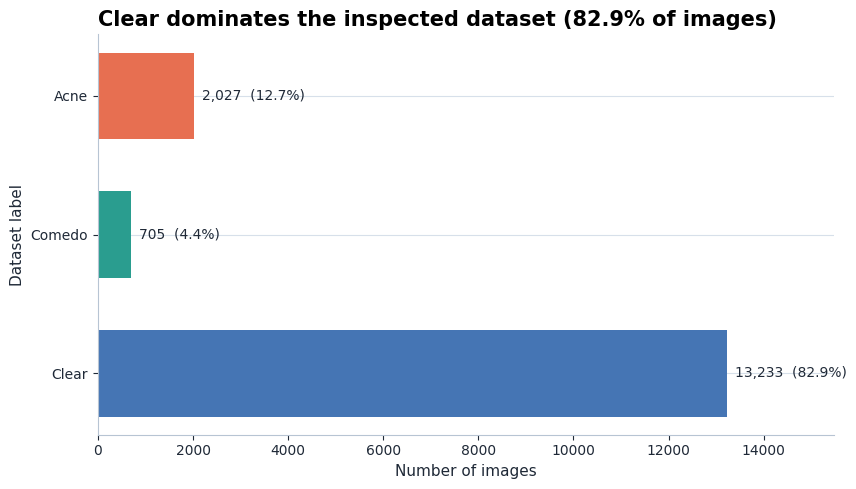

Saved chart: output/charts/eda_class_distribution.png


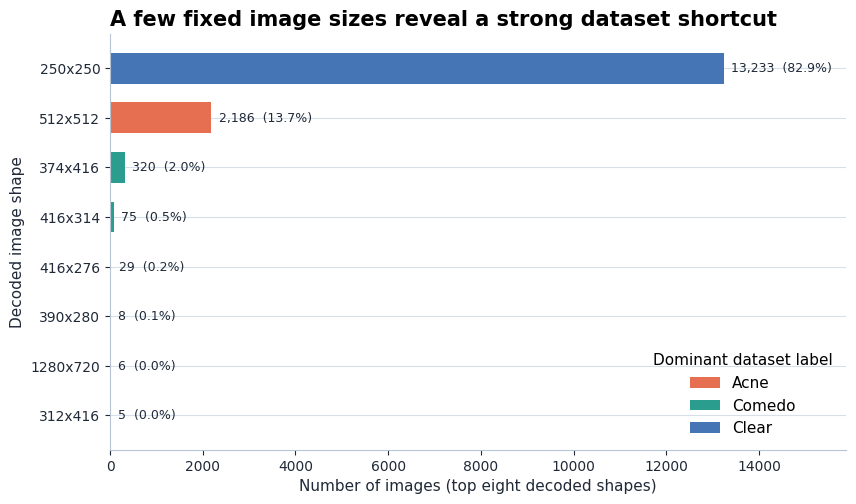

Saved chart: output/charts/eda_dimensions_by_label.png


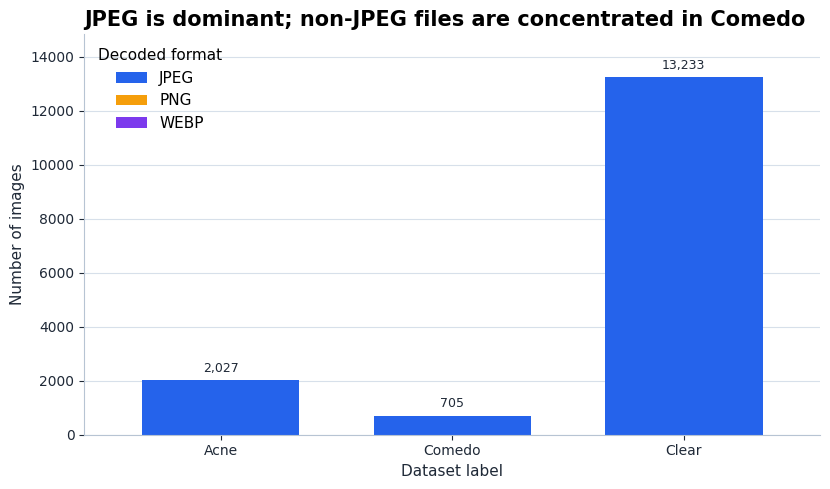

Saved chart: output/charts/eda_formats_by_label.png


,label,images,share_percent
0,Acne,2027,12.70%
1,Comedo,705,4.42%
2,Clear,13233,82.89%


,label,actual_format,mode,images
0,Acne,JPEG,RGB,2027
1,Clear,JPEG,RGB,13233
2,Comedo,JPEG,RGB,697
3,Comedo,PNG,P,1
4,Comedo,PNG,RGBA,1
5,Comedo,WEBP,RGB,6


,label,width,height,images,shape
1,Clear,250,250,13233,250x250
0,Acne,512,512,2027,512x512
16,Comedo,374,416,320,374x416
37,Comedo,512,512,159,512x512
29,Comedo,416,314,75,416x314
23,Comedo,416,276,29,416x276
17,Comedo,390,280,8,390x280
77,Comedo,1280,720,6,1280x720
11,Comedo,312,416,5,312x416
20,Comedo,415,264,5,415x264


In [5]:
label_counts = manifest['label'].value_counts().reindex(CLASS_NAMES, fill_value=0)
label_counts_table = label_counts.rename_axis('label').reset_index(name='images')
label_counts_table['share_percent'] = 100 * label_counts_table['images'] / len(manifest)
save_table(label_counts_table, 'eda_label_counts.csv')

format_table = (
    manifest.groupby(['label', 'actual_format', 'mode'], dropna=False)
    .size().rename('images').reset_index()
)
save_table(format_table, 'eda_format_summary.csv')

dimension_table = (
    manifest.groupby(['label', 'width', 'height'], dropna=False)
    .size().rename('images').reset_index()
)
dimension_table['shape'] = dimension_table['width'].astype('Int64').astype(str) + 'x' + dimension_table['height'].astype('Int64').astype(str)
save_table(dimension_table, 'eda_dimension_summary.csv')

issues_table = pd.DataFrame([
    {'check': 'unreadable files', 'count': int(manifest.load_error.notna().sum())},
    {'check': 'extension/format mismatches', 'count': int((manifest.actual_format.str.lower() != manifest.path.str.extract(r'\.([^.]+)$')[0].str.lower()).sum())},
    {'check': 'images with EXIF metadata', 'count': int((manifest.exif_count > 0).sum())},
])
save_table(issues_table, 'eda_integrity_checks.csv')

# A direct-label horizontal bar chart makes the imbalance readable without a pie chart.
figure, axis = plt.subplots(figsize=(9.5, 5.2))
bars = axis.barh(label_counts.index, label_counts.values, color=[CLASS_COLORS[label] for label in CLASS_NAMES], height=0.62)
axis.invert_yaxis()
axis.set_title(f"{label_counts.idxmax()} dominates the inspected dataset ({label_counts.max() / len(manifest):.1%} of images)", loc='left')
axis.set_xlabel('Number of images')
axis.set_ylabel('Dataset label')
axis.set_xlim(0, label_counts.max() * 1.17)
for bar, value in zip(bars, label_counts.values):
    share = value / len(manifest)
    axis.text(value + label_counts.max() * 0.012, bar.get_y() + bar.get_height() / 2, f'{value:,}  ({share:.1%})', va='center', fontsize=10, color=CHART_COLORS['text'])
style_axes(axis)
finish_figure(figure, 'eda_class_distribution.png')

# 83 distinct shapes make a grouped chart unreadable. Show the eight dominant shapes and label their dominant class.
shape_summary = dimension_table.groupby('shape', as_index=False)['images'].sum().sort_values('images', ascending=False).head(8).sort_values('images')
dominant_label_by_shape = (
    dimension_table.sort_values(['shape', 'images'], ascending=[True, False])
    .drop_duplicates('shape')
    .set_index('shape')['label']
    .to_dict()
)
figure, axis = plt.subplots(figsize=(9.5, 5.4))
shape_colors = [CLASS_COLORS[dominant_label_by_shape[shape]] for shape in shape_summary['shape']]
bars = axis.barh(shape_summary['shape'], shape_summary['images'], color=shape_colors, height=0.62)
axis.set_title('A few fixed image sizes reveal a strong dataset shortcut', loc='left')
axis.set_xlabel('Number of images (top eight decoded shapes)')
axis.set_ylabel('Decoded image shape')
axis.set_xlim(0, shape_summary.images.max() * 1.20)
for bar, value in zip(bars, shape_summary['images']):
    axis.text(value + shape_summary.images.max() * 0.012, bar.get_y() + bar.get_height() / 2, f'{value:,}  ({value / len(manifest):.1%})', va='center', fontsize=9, color=CHART_COLORS['text'])
legend_handles = [Patch(facecolor=CLASS_COLORS[label], label=label) for label in CLASS_NAMES]
axis.legend(handles=legend_handles, title='Dominant dataset label', frameon=False, loc='lower right')
style_axes(axis)
finish_figure(figure, 'eda_dimensions_by_label.png')

format_pivot = pd.crosstab(manifest['label'], manifest['actual_format']).reindex(CLASS_NAMES, fill_value=0)
format_columns = [column for column in ['JPEG', 'PNG', 'WEBP'] if column in format_pivot.columns]
format_pivot = format_pivot.reindex(columns=format_columns, fill_value=0)
figure, axis = plt.subplots(figsize=(9.5, 5.2))
format_colors = [FORMAT_COLORS.get(column, CHART_COLORS['muted']) for column in format_columns]
format_pivot.plot(kind='bar', stacked=True, ax=axis, color=format_colors, width=0.68)
format_totals = format_pivot.sum(axis=1)
axis.set_title('JPEG is dominant; non-JPEG files are concentrated in Comedo', loc='left')
axis.set_xlabel('Dataset label')
axis.set_ylabel('Number of images')
axis.tick_params(axis='x', rotation=0)
axis.set_ylim(0, format_totals.max() * 1.12)
axis.legend(title='Decoded format', frameon=False, loc='upper left')
for index, total in enumerate(format_totals):
    axis.text(index, total + format_totals.max() * 0.015, f'{int(total):,}', ha='center', va='bottom', fontsize=9, color=CHART_COLORS['text'])
style_axes(axis)
finish_figure(figure, 'eda_formats_by_label.png')

display(style_table(label_counts_table, gradient_columns=['images', 'share_percent']).format({'share_percent': '{:.2f}%'}))
display(style_table(format_table, gradient_columns=['images']))
display(style_table(dimension_table.sort_values('images', ascending=False).head(15), gradient_columns=['images']))

## 5. Evidence-based EDA conclusion and modelling decision

The next output converts the charts into a decision record rather than leaving interpretation implicit. A highly imbalanced label distribution requires macro-F1 and balanced accuracy in addition to accuracy. If dimensions predict labels almost perfectly or Clear has a recognizable source signature, a naive random image split would overstate generalization, so the experiment must group related images before splitting.

In [6]:
exact_duplicate_rows = manifest[manifest.duplicated('sha256', keep=False)].sort_values('sha256')
duplicate_groups = int(exact_duplicate_rows['sha256'].nunique())
source_groups = manifest.groupby('source_stem')
cross_split_source_stems = source_groups.filter(lambda frame: frame.original_split.nunique() > 1)
cross_class_source_stems = source_groups.filter(lambda frame: frame.label.nunique() > 1)

clear_manifest = manifest[manifest.label.eq('Clear')].copy()
clear_manifest['clear_subject'] = clear_manifest.filename.map(clear_subject)
clear_like_lfw = (
    len(clear_manifest) == 13233
    and clear_manifest[['width', 'height']].drop_duplicates().shape[0] == 1
    and tuple(clear_manifest[['width', 'height']].drop_duplicates().iloc[0]) == (250, 250)
    and clear_manifest.clear_subject.nunique() == 5749
)

def dimension_only_prediction(row: pd.Series) -> str:
    if row.width == 250 and row.height == 250:
        return 'Clear'
    if row.width == 512 and row.height == 512:
        return 'Acne'
    return 'Comedo'

manifest['dimension_only_prediction'] = manifest.apply(dimension_only_prediction, axis=1)
dimension_accuracy = float((manifest.dimension_only_prediction == manifest.label).mean())

audit_summary = {
    'files': int(len(manifest)),
    'bytes': int(manifest.bytes.sum()),
    'unreadable_files': int(manifest.load_error.notna().sum()),
    'exact_duplicate_groups': duplicate_groups,
    'exact_duplicate_files': int(len(exact_duplicate_rows)),
    'cross_split_source_stems': int(cross_split_source_stems.source_stem.nunique()),
    'cross_class_source_stems': int(cross_class_source_stems.source_stem.nunique()),
    'clear_lfw_like_signature': bool(clear_like_lfw),
    'dimension_only_accuracy': dimension_accuracy,
    'label_counts': {key: int(value) for key, value in label_counts.items()},
}
save_json(audit_summary, 'audit_summary.json')

warning_lines = []
if clear_like_lfw:
    warning_lines.append('The Clear folder matches a strong LFW-like count/shape/subject signature; this is not verified clinical clear-skin data.')
if dimension_accuracy >= 0.95:
    warning_lines.append(f'A dimensions-only rule reaches {dimension_accuracy:.2%}; image dimensions are a major shortcut in this dataset.')
if label_counts.max() / label_counts.min() >= 5:
    warning_lines.append('The class distribution is materially imbalanced, so class weights and macro-averaged metrics are required.')
warning_lines.append('Decision: remove exact duplicate extras, group related source identities, reserve 20% as an untouched test set, and report limitations with every result.')
display(Markdown('### EDA conclusion\n\n' + '\n'.join(f'- {line}' for line in warning_lines)))
save_text('\n'.join(f'- {line}' for line in warning_lines), 'eda_conclusion.md')
if clear_like_lfw and not ALLOW_EXPLORATORY_CURRENT_DATA:
    raise RuntimeError('Exploratory current dataset use is disabled by ALLOW_EXPLORATORY_CURRENT_DATA.')

Saved JSON: output/tables/audit_summary.json


### EDA conclusion

- The Clear folder matches a strong LFW-like count/shape/subject signature; this is not verified clinical clear-skin data.
- A dimensions-only rule reaches 99.00%; image dimensions are a major shortcut in this dataset.
- The class distribution is materially imbalanced, so class weights and macro-averaged metrics are required.
- Decision: remove exact duplicate extras, group related source identities, reserve 20% as an untouched test set, and report limitations with every result.

Saved text: output/tables/eda_conclusion.md


## 6. Create a grouped 80/20 train–test split and an internal validation split

The test set is created first with `StratifiedGroupKFold`, targeting 20% of the deduplicated rows while preserving label proportions as far as group constraints allow. The remaining 80% is the training pool. Only that pool is subdivided into a small validation set for early stopping; the test set is not used to tune the model.

In [7]:
clean_manifest = manifest[manifest.load_error.isna()].drop_duplicates('sha256', keep='first').copy()
clean_manifest['label_id'] = clean_manifest.label.map(CLASS_TO_ID)

def make_group_id(row: pd.Series) -> str:
    if row.label == 'Clear':
        return f'clear:{clear_subject(row.filename)}'
    return f'source:{row.source_stem}'

clean_manifest['group_id'] = clean_manifest.apply(make_group_id, axis=1)

test_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_pool_indices, test_indices = next(
    test_splitter.split(clean_manifest, clean_manifest.label_id, clean_manifest.group_id)
)
train_pool_df = clean_manifest.iloc[train_pool_indices].copy()
test_df = clean_manifest.iloc[test_indices].copy()

validation_splits = max(2, round(1 / VALIDATION_FRACTION_OF_TRAIN_POOL))
validation_splitter = StratifiedGroupKFold(n_splits=validation_splits, shuffle=True, random_state=SEED + 1)
train_indices, validation_indices = next(
    validation_splitter.split(train_pool_df, train_pool_df.label_id, train_pool_df.group_id)
)
train_df = train_pool_df.iloc[train_indices].copy()
val_df = train_pool_df.iloc[validation_indices].copy()

clean_manifest['split'] = 'excluded'
clean_manifest.loc[train_df.index, 'split'] = 'train'
clean_manifest.loc[val_df.index, 'split'] = 'validation'
clean_manifest.loc[test_df.index, 'split'] = 'test'
save_table(clean_manifest, 'clean_split_manifest.csv')

split_counts = clean_manifest.groupby(['split', 'label']).size().rename('images').reset_index()
split_counts = split_counts[split_counts.split.isin(['train', 'validation', 'test'])]
save_table(split_counts, 'split_class_counts.csv')

overlap_pairs = {}
split_groups = {name: set(frame.group_id) for name, frame in [('train', train_df), ('validation', val_df), ('test', test_df)]}
for first, second in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    overlap_pairs[f'{first}:{second}'] = len(split_groups[first] & split_groups[second])
assert all(value == 0 for value in overlap_pairs.values()), f'Group leakage detected: {overlap_pairs}'

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.08),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class AcneDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, transform: transforms.Compose) -> None:
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int):
        row = self.frame.iloc[index]
        image_path = ROOT / row.path
        with Image.open(image_path) as image:
            image = ImageOps.exif_transpose(image).convert('RGB')
        return self.transform(image), int(row.label_id)

train_loader = DataLoader(AcneDataset(train_df, train_transform), batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
val_loader = DataLoader(AcneDataset(val_df, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
test_loader = DataLoader(AcneDataset(test_df, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

train_counts = train_df.label_id.value_counts().reindex(range(len(CLASS_NAMES)), fill_value=0).to_numpy()
class_weights = len(train_df) / (len(CLASS_NAMES) * np.maximum(train_counts, 1))
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)

split_summary = pd.DataFrame([
    {'split': 'train', 'images': len(train_df), 'share_of_clean_data_percent': 100 * len(train_df) / len(clean_manifest), 'groups': train_df.group_id.nunique()},
    {'split': 'validation', 'images': len(val_df), 'share_of_clean_data_percent': 100 * len(val_df) / len(clean_manifest), 'groups': val_df.group_id.nunique()},
    {'split': 'test', 'images': len(test_df), 'share_of_clean_data_percent': 100 * len(test_df) / len(clean_manifest), 'groups': test_df.group_id.nunique()},
])
save_table(split_summary, 'split_summary.csv')
display(style_table(split_summary, gradient_columns=['images', 'share_of_clean_data_percent', 'groups']).format({'share_of_clean_data_percent': '{:.2f}%'}))
print(f'Clean rows after exact deduplication: {len(clean_manifest):,}')
print(f'Test fraction achieved: {len(test_df) / len(clean_manifest):.2%}')
print(f'Group overlap check: {overlap_pairs}')
print(f'Training class weights: {dict(zip(CLASS_NAMES, class_weights.round(4)))}')

Saved table: output/tables/clean_split_manifest.csv
Saved table: output/tables/split_class_counts.csv
Saved table: output/tables/split_summary.csv


,split,images,share_of_clean_data_percent,groups
0,train,11486,72.00%,5146
1,validation,1276,8.00%,565
2,test,3191,20.00%,1421


Clean rows after exact deduplication: 15,953
Test fraction achieved: 20.00%
Group overlap check: {'train:validation': 0, 'train:test': 0, 'validation:test': 0}
Training class weights: {'Acne': np.float64(2.6296), 'Comedo': np.float64(7.6117), 'Clear': np.float64(0.4019)}


## 7. Visualise the split and verify the test boundary

This section makes the split auditable. The class-count chart should show that every split contains the three labels, while the table reports row share and group count. The final assertion confirms that no source identity or normalized source group appears in more than one partition.

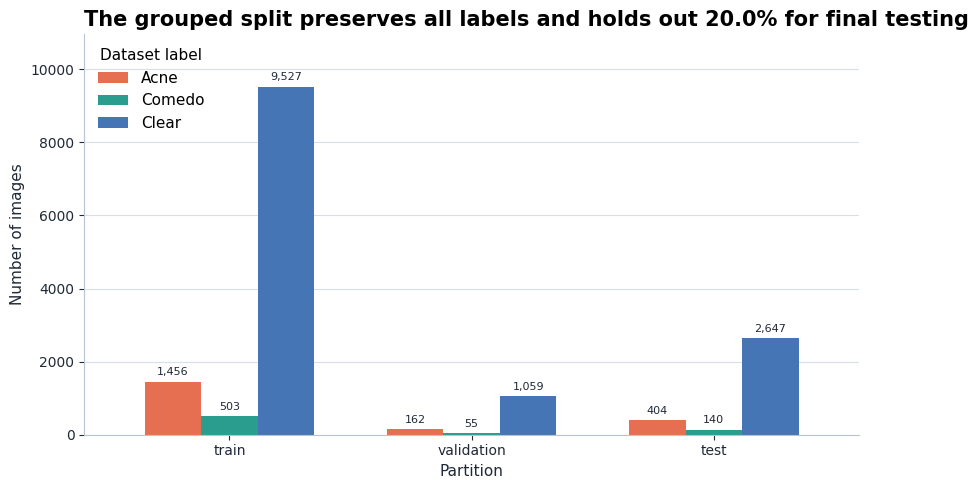

Saved chart: output/charts/split_class_counts.png
Untouched test rows: 3,191 (20.00%)
Train-pool rows: 12,762 (80.00%)
Internal validation rows: 1,276 (8.00%)
No group overlap: True


In [8]:
split_order = ['train', 'validation', 'test']
split_pivot = split_counts.pivot(index='split', columns='label', values='images').reindex(index=split_order, columns=CLASS_NAMES, fill_value=0)
figure, axis = plt.subplots(figsize=(10, 5.2))
split_pivot.plot(kind='bar', ax=axis, color=[CLASS_COLORS[label] for label in CLASS_NAMES], width=0.70)
axis.set_title(f'The grouped split preserves all labels and holds out {len(test_df) / len(clean_manifest):.1%} for final testing', loc='left')
axis.set_xlabel('Partition')
axis.set_ylabel('Number of images')
axis.tick_params(axis='x', rotation=0)
axis.set_ylim(0, split_pivot.to_numpy().max() * 1.15)
axis.legend(title='Dataset label', frameon=False, loc='upper left')
for container in axis.containers:
    for bar in container:
        value = bar.get_height()
        if value > 0:
            axis.text(bar.get_x() + bar.get_width() / 2, value + split_pivot.to_numpy().max() * 0.012, f'{int(value):,}', ha='center', va='bottom', fontsize=8, color=CHART_COLORS['text'])
style_axes(axis)
finish_figure(figure, 'split_class_counts.png')

print(f'Untouched test rows: {len(test_df):,} ({len(test_df) / len(clean_manifest):.2%})')
print(f'Train-pool rows: {len(train_pool_df):,} ({len(train_pool_df) / len(clean_manifest):.2%})')
print(f'Internal validation rows: {len(val_df):,} ({len(val_df) / len(clean_manifest):.2%})')
print('No group overlap:', all(value == 0 for value in overlap_pairs.values()))

## 8. Define the CNN architecture and training loop

The primary model is EfficientNet-B0, a convolutional network with learned feature-extraction blocks followed by a three-unit classification head. ImageNet weights are used when available and the code falls back to random initialisation if the environment cannot download them. A compact custom CNN is included as an optional baseline, but it is disabled by default to keep the main experiment focused and reproducible.

In [9]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes: int) -> None:
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.35), nn.Linear(256, num_classes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.features(x))

def build_model(model_name: str, *, pretrained: bool = USE_IMAGENET_WEIGHTS) -> nn.Module:
    if model_name == 'custom_cnn':
        return SmallCNN(len(CLASS_NAMES))
    if model_name == 'efficientnet_b0':
        weights = None
        if pretrained:
            try:
                weights = models.EfficientNet_B0_Weights.DEFAULT
            except Exception as exc:
                warnings.warn(f'Could not resolve ImageNet weights: {exc}')
        try:
            model = models.efficientnet_b0(weights=weights)
        except Exception as exc:
            warnings.warn(f'Pretrained weights unavailable; using random initialisation: {exc}')
            model = models.efficientnet_b0(weights=None)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, len(CLASS_NAMES))
        return model
    raise ValueError(f'Unknown model: {model_name}')

def run_epoch(model, loader, criterion, optimizer=None, phase='eval'):
    is_training = optimizer is not None
    model.train(is_training)
    total_loss = 0.0
    targets, predictions, probabilities = [], [], []
    progress = tqdm(loader, desc=phase, leave=False, dynamic_ncols=True)
    for images, labels in progress:
        images = images.to(DEVICE, non_blocking=PIN_MEMORY)
        labels = labels.to(DEVICE, non_blocking=PIN_MEMORY)
        if is_training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(is_training):
            logits = model(images)
            loss = criterion(logits, labels)
            if is_training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
                optimizer.step()
        total_loss += loss.item() * images.size(0)
        targets.extend(labels.detach().cpu().numpy().tolist())
        predictions.extend(logits.argmax(1).detach().cpu().numpy().tolist())
        probabilities.append(torch.softmax(logits, dim=1).detach().cpu().numpy())
        progress.set_postfix(loss=f'{loss.item():.3f}')
    probabilities = np.concatenate(probabilities, axis=0)
    return {
        'loss': total_loss / max(len(loader.dataset), 1),
        'accuracy': accuracy_score(targets, predictions),
        'macro_f1': f1_score(targets, predictions, average='macro', zero_division=0),
        'targets': np.asarray(targets),
        'predictions': np.asarray(predictions),
        'probabilities': probabilities,
    }

def save_checkpoint(payload: dict, *paths: Path) -> None:
    for path in paths:
        torch.save(payload, path)

def fit_model(model_name: str):
    model = build_model(model_name, pretrained=USE_IMAGENET_WEIGHTS).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=1, factor=0.3)
    best_path = MODEL_DIR / f'{model_name}_best.pt'
    last_path = MODEL_DIR / f'{model_name}_last.pt'
    output_best_path = OUTPUT_MODEL_DIR / f'{model_name}_best.pt'
    output_last_path = OUTPUT_MODEL_DIR / f'{model_name}_last.pt'
    history, best_score, stale_epochs = [], -1.0, 0
    start_epoch = 1
    if RESUME_FROM_LAST:
        if not last_path.exists():
            raise FileNotFoundError(f'Cannot resume: last checkpoint not found at {relative_path(last_path)}')
        resume_checkpoint = torch.load(last_path, map_location=DEVICE)
        if resume_checkpoint.get('model_name') != model_name or resume_checkpoint.get('class_names') != CLASS_NAMES:
            raise RuntimeError('Cannot resume: the last checkpoint does not match the selected model contract.')
        model.load_state_dict(resume_checkpoint['model_state'])
        optimizer.load_state_dict(resume_checkpoint['optimizer_state'])
        scheduler.load_state_dict(resume_checkpoint['scheduler_state'])
        history = list(resume_checkpoint.get('history', []))
        best_score = float(resume_checkpoint.get('best_validation_macro_f1', -1.0))
        stale_epochs = int(resume_checkpoint.get('stale_epochs', 0))
        start_epoch = int(resume_checkpoint['epoch']) + 1
        if start_epoch > EPOCHS:
            raise RuntimeError(f'Cannot resume: checkpoint already completed Epoch {start_epoch - 1}, above maximum {EPOCHS}.')
        print(f'Resuming {model_name} from Epoch {start_epoch - 1}; best validation macro-F1: {best_score:.4f}.')

    print(f'Starting {model_name} on {DEVICE} for up to {EPOCHS} epochs.')
    for epoch in range(start_epoch, EPOCHS + 1):
        epoch_start = time.time()
        train_result = run_epoch(model, train_loader, criterion, optimizer, phase=f'epoch {epoch}/{EPOCHS} train')
        val_result = run_epoch(model, val_loader, criterion, phase=f'epoch {epoch}/{EPOCHS} validation')
        scheduler.step(val_result['macro_f1'])
        row = {
            'epoch': epoch,
            'learning_rate': optimizer.param_groups[0]['lr'],
            'train_loss': train_result['loss'],
            'validation_loss': val_result['loss'],
            'train_accuracy': train_result['accuracy'],
            'validation_accuracy': val_result['accuracy'],
            'train_macro_f1': train_result['macro_f1'],
            'validation_macro_f1': val_result['macro_f1'],
            'seconds': time.time() - epoch_start,
        }
        history.append(row)
        checkpoint_payload = {
            'model_state': model.state_dict(),
            'optimizer_state': optimizer.state_dict(),
            'scheduler_state': scheduler.state_dict(),
            'model_name': model_name,
            'class_names': CLASS_NAMES,
            'image_size': IMAGE_SIZE,
            'epoch': epoch,
            'best_validation_macro_f1': max(best_score, val_result['macro_f1']),
            'stale_epochs': stale_epochs,
            'run_id': RUN_ID,
            'history': history,
        }
        save_checkpoint(checkpoint_payload, last_path, output_last_path)
        history_frame = pd.DataFrame(history)
        save_table(history_frame, f'{model_name}_training_history.csv')
        print(
            f"Epoch {epoch:02d}/{EPOCHS} | train loss {row['train_loss']:.4f} | "
            f"val loss {row['validation_loss']:.4f} | train macro-F1 {row['train_macro_f1']:.4f} | "
            f"val macro-F1 {row['validation_macro_f1']:.4f} | {row['seconds']:.1f}s"
        )
        if val_result['macro_f1'] > best_score:
            best_score = val_result['macro_f1']
            stale_epochs = 0
            checkpoint_payload['best_validation_macro_f1'] = best_score
            checkpoint_payload['stale_epochs'] = stale_epochs
            save_checkpoint(checkpoint_payload, best_path, output_best_path)
            print(f'  Saved new best checkpoint: {relative_path(best_path)}')
        else:
            stale_epochs += 1
            checkpoint_payload['stale_epochs'] = stale_epochs
            if stale_epochs >= PATIENCE:
                print(f'Early stopping after {stale_epochs} non-improving validation epochs.')
                save_checkpoint(checkpoint_payload, last_path, output_last_path)
                write_run_state('running', epoch_completed=epoch, best_validation_macro_f1=best_score, latest_checkpoint=relative_path(last_path), message='Early stopping reached; final evaluation and export are pending.')
                break
        save_checkpoint(checkpoint_payload, last_path, output_last_path)
        write_run_state('running', epoch_completed=epoch, best_validation_macro_f1=best_score, latest_checkpoint=relative_path(last_path), message='Training checkpoint saved; final evaluation and export are pending.')
    history_frame = pd.DataFrame(history)
    return best_path, history_frame

## 9. Train the selected model and save checkpoints during training

Each epoch runs a visible training progress bar followed by validation. After every epoch, the last checkpoint and training-history table are saved; whenever validation macro-F1 improves, the best checkpoint is saved as well. This makes the run recoverable and prevents the final model from depending on an unsaved in-memory state.

Starting efficientnet_b0 on cuda for up to 12 epochs.


Saved table: output/tables/efficientnet_b0_training_history.csv
Epoch 01/12 | train loss 0.2200 | val loss 0.0398 | train macro-F1 0.8815 | val macro-F1 0.9520 | 147.3s
  Saved new best checkpoint: model/efficientnet_b0_best.pt


Saved table: output/tables/efficientnet_b0_training_history.csv
Epoch 02/12 | train loss 0.0996 | val loss 0.0304 | train macro-F1 0.9562 | val macro-F1 0.9554 | 150.9s
  Saved new best checkpoint: model/efficientnet_b0_best.pt


Saved table: output/tables/efficientnet_b0_training_history.csv
Epoch 03/12 | train loss 0.0763 | val loss 0.0333 | train macro-F1 0.9650 | val macro-F1 0.9494 | 156.7s


Saved table: output/tables/efficientnet_b0_training_history.csv
Epoch 04/12 | train loss 0.0543 | val loss 0.0279 | train macro-F1 0.9776 | val macro-F1 0.9567 | 158.6s
  Saved new best checkpoint: model/efficientnet_b0_best.pt


Saved table: output/tables/efficientnet_b0_training_history.csv
Epoch 05/12 | train loss 0.0505 | val loss 0.0364 | train macro-F1 0.9747 | val macro-F1 0.9509 | 156.2s


Saved table: output/tables/efficientnet_b0_training_history.csv
Epoch 06/12 | train loss 0.0371 | val loss 0.0726 | train macro-F1 0.9848 | val macro-F1 0.9185 | 154.4s


Saved table: output/tables/efficientnet_b0_training_history.csv
Epoch 07/12 | train loss 0.0170 | val loss 0.0518 | train macro-F1 0.9929 | val macro-F1 0.9494 | 153.4s
Early stopping after 3 non-improving validation epochs.
Custom CNN baseline is available in code but disabled for the primary run.
Final checkpoint ready: model/efficientnet_b0_best.pt


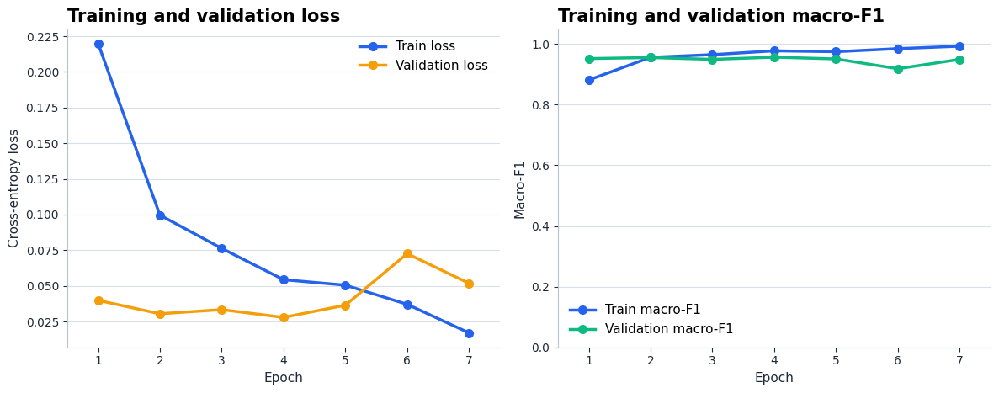

Saved chart: output/charts/training_history.png


,epoch,learning_rate,train_loss,validation_loss,train_accuracy,validation_accuracy,train_macro_f1,validation_macro_f1,seconds
0,1,0.0003,0.2200,0.0398,0.9713,0.9890,0.8815,0.9520,147.3403
1,2,0.0003,0.0996,0.0304,0.9908,0.9914,0.9562,0.9554,150.9416
2,3,0.0003,0.0763,0.0333,0.9924,0.9906,0.9650,0.9494,156.7381
3,4,0.0003,0.0543,0.0279,0.9953,0.9922,0.9776,0.9567,158.6241
4,5,0.0003,0.0505,0.0364,0.9944,0.9898,0.9747,0.9509,156.1980
5,6,0.0001,0.0371,0.0726,0.9968,0.9859,0.9848,0.9185,154.3688
6,7,0.0001,0.0170,0.0518,0.9983,0.9906,0.9929,0.9494,153.4278


In [10]:
FINAL_MODEL_NAME = 'efficientnet_b0'
trained_checkpoints = {}
training_histories = {}

if RUN_TRAINING:
    trained_checkpoints[FINAL_MODEL_NAME], training_histories[FINAL_MODEL_NAME] = fit_model(FINAL_MODEL_NAME)
    if TRAIN_CUSTOM_BASELINE:
        trained_checkpoints['custom_cnn'], training_histories['custom_cnn'] = fit_model('custom_cnn')
    else:
        print('Custom CNN baseline is available in code but disabled for the primary run.')
else:
    print('RUN_TRAINING=False; using an existing checkpoint if available.')

FINAL_CHECKPOINT = MODEL_DIR / f'{FINAL_MODEL_NAME}_best.pt'
if not FINAL_CHECKPOINT.exists():
    raise FileNotFoundError(f'Final checkpoint not found: {FINAL_CHECKPOINT}')
print(f'Final checkpoint ready: {relative_path(FINAL_CHECKPOINT)}')

history_frame = training_histories.get(FINAL_MODEL_NAME)
if history_frame is None:
    history_path = TABLE_DIR / f'{FINAL_MODEL_NAME}_training_history.csv'
    if history_path.exists():
        history_frame = pd.read_csv(history_path)
if history_frame is not None and not history_frame.empty:
    epoch_values = history_frame['epoch'].astype(int).tolist()
    final_epoch = max(epoch_values)
    figure, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    axes[0].plot(history_frame['epoch'], history_frame['train_loss'], marker='o', linewidth=2.5, markersize=7, label='Train loss', color=CHART_COLORS['primary'])
    axes[0].plot(history_frame['epoch'], history_frame['validation_loss'], marker='o', linewidth=2.5, markersize=7, label='Validation loss', color=CHART_COLORS['secondary'])
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Cross-entropy loss')
    axes[0].set_title('Training and validation loss', loc='left')
    axes[0].legend(frameon=False)
    axes[0].set_xticks(epoch_values)
    axes[0].set_xlim(0.5, max(1.5, final_epoch + 0.5))
    axes[1].plot(history_frame['epoch'], history_frame['train_macro_f1'], marker='o', linewidth=2.5, markersize=7, label='Train macro-F1', color=CHART_COLORS['primary'])
    axes[1].plot(history_frame['epoch'], history_frame['validation_macro_f1'], marker='o', linewidth=2.5, markersize=7, label='Validation macro-F1', color=CHART_COLORS['tertiary'])
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Macro-F1')
    axes[1].set_ylim(0, 1.05)
    axes[1].set_title('Training and validation macro-F1', loc='left')
    axes[1].legend(frameon=False)
    axes[1].set_xticks(epoch_values)
    axes[1].set_xlim(0.5, max(1.5, final_epoch + 0.5))
    for axis in axes:
        style_axes(axis)
    figure.tight_layout()
    finish_figure(figure, 'training_history.png')
    display(style_table(history_frame, gradient_columns=['train_loss', 'validation_loss', 'train_macro_f1', 'validation_macro_f1']).format({column: '{:.4f}' for column in history_frame.columns if column != 'epoch'}))

## 10. Evaluate the train, validation, and untouched test partitions

The same saved best checkpoint is evaluated separately on all three partitions. The train row shows fit to seen examples, validation reflects the model-selection signal, and the untouched test row is the final unseen estimate. The test evaluation runs over every image in the held-out test partition, not only the later 20-image demonstration subset. Accuracy is reported together with balanced accuracy, macro precision/recall/F1, ROC-AUC, average precision, and log loss so class imbalance cannot be hidden by the majority `Clear` label.

Saved table: output/tables/efficientnet_b0_performance_by_split.csv


,model_name,split,rows,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,roc_auc_ovr,average_precision_macro,log_loss
0,efficientnet_b0,train,11486,0.9980,0.9912,0.9898,0.9912,0.9905,0.9980,1.0000,0.9992,0.0079
1,efficientnet_b0,validation,1276,0.9922,0.9394,0.9806,0.9394,0.9567,0.9919,0.9994,0.9908,0.0194
2,efficientnet_b0,test,3191,0.9893,0.9493,0.9454,0.9493,0.9473,0.9894,0.9989,0.9849,0.0273


Saved table: output/tables/efficientnet_b0_test_classification_report.csv


,label,precision,recall,f1-score,support
0,Acne,0.963,0.955,0.959,404.000000
1,Comedo,0.874,0.893,0.883,140.000000
2,Clear,1.000,1.000,1.000,2647.000000
3,accuracy,0.989,0.989,0.989,0.989345
4,macro avg,0.945,0.949,0.947,3191.000000
5,weighted avg,0.989,0.989,0.989,3191.000000


Saved table: output/tables/efficientnet_b0_test_predictions.csv
Saved JSON: output/tables/efficientnet_b0_test_metrics.json


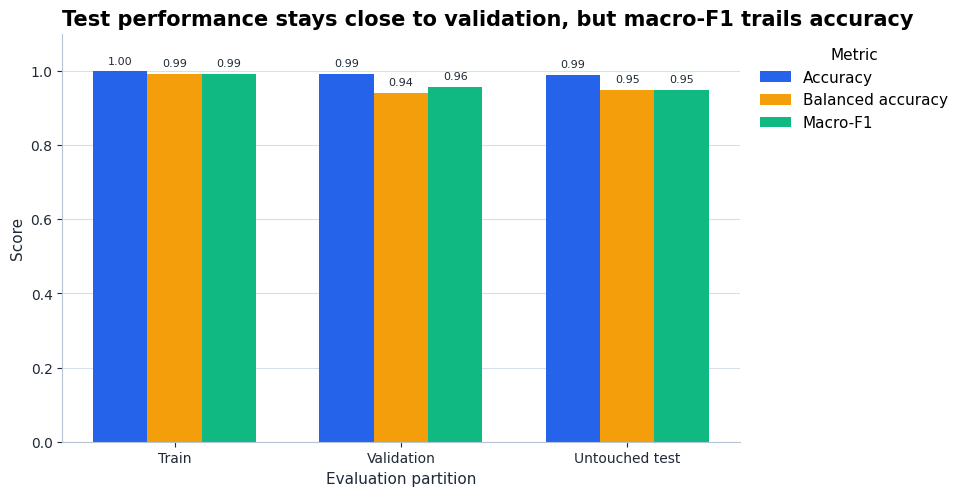

Saved chart: output/charts/evaluation_performance_comparison.png
Saved table: output/tables/efficientnet_b0_test_confusion_matrix.csv


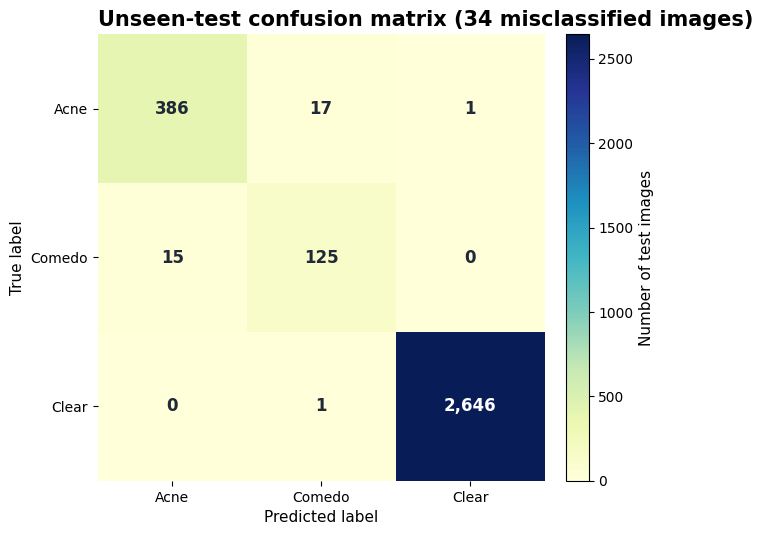

Saved chart: output/charts/evaluation_test_confusion_matrix.png


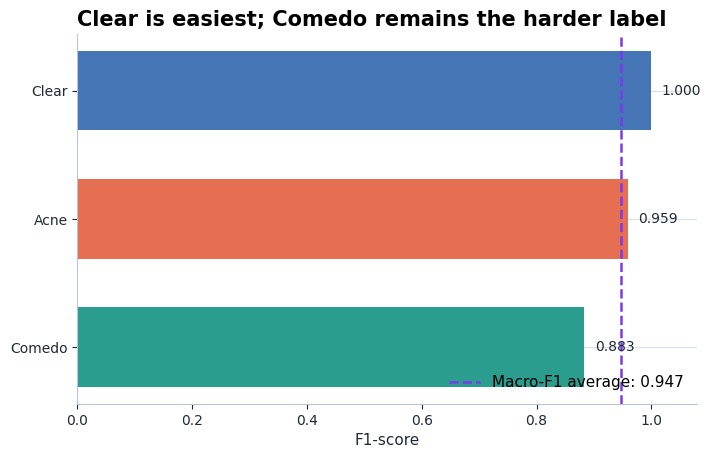

Saved chart: output/charts/evaluation_test_per_class_f1.png


WindowsPath('D:/academic assignment 2026/acne cnn/output/charts/evaluation_test_per_class_f1.png')

In [11]:
def load_trained_model(model_name: str) -> nn.Module:
    checkpoint_path = MODEL_DIR / f'{model_name}_best.pt'
    model = build_model(model_name, pretrained=False).to(DEVICE)
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(checkpoint.get('model_state', checkpoint))
    model.eval()
    return model

def metric_bundle(result: dict, split_name: str) -> dict:
    y_true, y_pred, y_prob = result['targets'], result['predictions'], result['probabilities']
    y_binary = label_binarize(y_true, classes=list(range(len(CLASS_NAMES))))
    return {
        'model_name': FINAL_MODEL_NAME,
        'split': split_name,
        'rows': int(len(y_true)),
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'balanced_accuracy': float(balanced_accuracy_score(y_true, y_pred)),
        'macro_precision': float(precision_score(y_true, y_pred, average='macro', zero_division=0)),
        'macro_recall': float(recall_score(y_true, y_pred, average='macro', zero_division=0)),
        'macro_f1': float(f1_score(y_true, y_pred, average='macro', zero_division=0)),
        'weighted_f1': float(f1_score(y_true, y_pred, average='weighted', zero_division=0)),
        'roc_auc_ovr': float(roc_auc_score(y_binary, y_prob, multi_class='ovr')),
        'average_precision_macro': float(average_precision_score(y_binary, y_prob, average='macro')),
        'log_loss': float(log_loss(y_true, y_prob, labels=list(range(len(CLASS_NAMES))))),
    }

final_model = load_trained_model(FINAL_MODEL_NAME)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
eval_loaders = {'train': DataLoader(AcneDataset(train_df, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY), 'validation': val_loader, 'test': test_loader}
split_results, metric_rows = {}, []
for split_name, loader in eval_loaders.items():
    split_results[split_name] = run_epoch(final_model, loader, criterion, phase=f'evaluate {split_name}')
    metric_rows.append(metric_bundle(split_results[split_name], split_name))

performance_table = pd.DataFrame(metric_rows)
save_table(performance_table, f'{FINAL_MODEL_NAME}_performance_by_split.csv')
display(style_table(performance_table, gradient_columns=['accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'weighted_f1']).format({column: '{:.4f}' for column in performance_table.columns if column not in ['model_name', 'split', 'rows']}))

test_result = split_results['test']
test_report = pd.DataFrame(classification_report(test_result['targets'], test_result['predictions'], labels=list(range(len(CLASS_NAMES))), target_names=CLASS_NAMES, output_dict=True, zero_division=0)).T.reset_index(names='label')
save_table(test_report, f'{FINAL_MODEL_NAME}_test_classification_report.csv')
display(style_table(test_report, gradient_columns=['precision', 'recall', 'f1-score']).format({column: '{:.3f}' for column in ['precision', 'recall', 'f1-score'] if column in test_report.columns}))

test_predictions = test_df[['path', 'label', 'label_id', 'group_id']].reset_index(drop=True).copy()
test_predictions['predicted_label'] = [CLASS_NAMES[index] for index in test_result['predictions']]
test_predictions['correct'] = test_predictions['label'] == test_predictions['predicted_label']
for index, label in enumerate(CLASS_NAMES):
    test_predictions[f'prob_{label}'] = test_result['probabilities'][:, index]
save_table(test_predictions, f'{FINAL_MODEL_NAME}_test_predictions.csv')

test_metrics = next(row for row in metric_rows if row['split'] == 'test')
save_json(test_metrics, f'{FINAL_MODEL_NAME}_test_metrics.json')

performance_for_chart = performance_table.set_index('split').reindex(['train', 'validation', 'test'])[['accuracy', 'balanced_accuracy', 'macro_f1']]
metric_labels = {'accuracy': 'Accuracy', 'balanced_accuracy': 'Balanced accuracy', 'macro_f1': 'Macro-F1'}
figure, axis = plt.subplots(figsize=(10.5, 5.3))
x_positions = np.arange(len(performance_for_chart.index))
bar_width = 0.24
for offset, metric in enumerate(['accuracy', 'balanced_accuracy', 'macro_f1']):
    values = performance_for_chart[metric].to_numpy()
    bars = axis.bar(x_positions + (offset - 1) * bar_width, values, width=bar_width, label=metric_labels[metric], color=METRIC_COLORS[metric])
    for bar, value in zip(bars, values):
        axis.text(bar.get_x() + bar.get_width() / 2, value + 0.015, f'{value:.2f}', ha='center', va='bottom', fontsize=8, color=CHART_COLORS['text'])
axis.set_title('Test performance stays close to validation, but macro-F1 trails accuracy', loc='left')
axis.set_xlabel('Evaluation partition')
axis.set_ylabel('Score')
axis.set_xticks(x_positions, ['Train', 'Validation', 'Untouched test'])
axis.set_ylim(0, 1.10)
axis.legend(title='Metric', frameon=False, loc='upper left', bbox_to_anchor=(1.01, 1.0))
style_axes(axis)
figure.subplots_adjust(right=0.77)
finish_figure(figure, 'evaluation_performance_comparison.png')

matrix = confusion_matrix(test_result['targets'], test_result['predictions'], labels=list(range(len(CLASS_NAMES))))
matrix_frame = pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES)
save_table(matrix_frame.reset_index(names='true_label'), f'{FINAL_MODEL_NAME}_test_confusion_matrix.csv')
figure, axis = plt.subplots(figsize=(7, 5.8))
image = axis.imshow(matrix, cmap='YlGnBu', vmin=0)
colorbar = figure.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
colorbar.set_label('Number of test images')
axis.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES)
axis.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
axis.set_xlabel('Predicted label')
axis.set_ylabel('True label')
off_diagonal = int(matrix.sum() - np.trace(matrix))
axis.set_title(f'Unseen-test confusion matrix ({off_diagonal} misclassified images)', loc='left')
threshold = matrix.max() * 0.45
for row_index in range(matrix.shape[0]):
    for column_index in range(matrix.shape[1]):
        value = matrix[row_index, column_index]
        axis.text(column_index, row_index, f'{value:,}', ha='center', va='center', color='white' if value > threshold else CHART_COLORS['text'], fontweight='bold', fontsize=12)
axis.set_facecolor('#F8FBFF')
axis.spines[:].set_visible(False)
finish_figure(figure, 'evaluation_test_confusion_matrix.png')

per_class = test_report[test_report['label'].isin(CLASS_NAMES)].set_index('label').reindex(CLASS_NAMES).dropna().sort_values('f1-score')
figure, axis = plt.subplots(figsize=(8, 4.8))
bars = axis.barh(per_class.index, per_class['f1-score'], color=[CLASS_COLORS[label] for label in per_class.index], height=0.62)
axis.set_xlim(0, 1.08)
axis.set_xlabel('F1-score')
axis.set_title('Clear is easiest; Comedo remains the harder label', loc='left')
axis.axvline(test_metrics['macro_f1'], color=CHART_COLORS['accent'], linestyle='--', linewidth=1.8, label=f"Macro-F1 average: {test_metrics['macro_f1']:.3f}")
for bar, value in zip(bars, per_class['f1-score']):
    axis.text(value + 0.018, bar.get_y() + bar.get_height() / 2, f'{value:.3f}', va='center', fontsize=10, color=CHART_COLORS['text'])
axis.legend(frameon=False, loc='lower right')
style_axes(axis)
finish_figure(figure, 'evaluation_test_per_class_f1.png')

## 11. 50 stratified unseen samples, 20 detailed predictions, and Grad-CAM -- not YOLO detection

This project uses EfficientNet-B0 for one label per image: `Acne`, `Comedo`, or `Clear`. The notebook creates a reproducible gallery of 50 distinct images from the untouched test partition: 20 Acne, 15 Comedo, and 15 Clear. This is a balanced demonstration set, not a claim about real-world prevalence. It also evaluates a smaller, clearly labelled 20-image subset in detail and saves every input path, true label, predicted label, correctness flag, confidence, and all three class scores.

The model is not a YOLO-style object detector because the supplied data has no bounding-box or segmentation annotations. Grad-CAM overlays are included for the 20-image detailed subset, but they are coarse class-attention maps: they do not identify exact acne spots, count lesions, or draw multiple bounding boxes. Exact spot localization would require lesion-level annotations and a separate YOLO or segmentation model. The full 3,191-image test metrics in the previous section remain the formal evaluation; the 20-image subset is only an easy-to-inspect professor demonstration.

Saved table: output/tables/professor_50_test_samples.csv
Saved table: output/tables/professor_50_summary.csv


### 50-image professor gallery

The gallery is stratified for visibility: 20 Acne, 15 Comedo, and 15 Clear. It is not a replacement for the full test evaluation.

,sample_set,rows,accuracy,balanced_accuracy,macro_f1
0,professor_50_stratified_gallery,50,0.980,0.978,0.980


,sample_id,path,label,predicted_label,correct,confidence
0,professor_001,dataset/Acne/Train/Acne/acne-comedones-57-v2__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDE3XQ_JPG_jpg.rf.9f7cdf5929d3eb21c56012128c60b0c9.jpg,Acne,Acne,True,0.999
1,professor_002,dataset/Acne/Train/Acne/acne-face-1-28__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDFd_jpg.rf.9aa9f2a161bc148ad8bb999449bdd177.jpg,Acne,Acne,True,1.000
2,professor_003,dataset/Acne/Train/Acne/acne-face-15__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDFd_jpg.rf.104a3b75cf9b66918bae2c9a81dbf563.jpg,Acne,Acne,True,1.000
3,professor_004,dataset/Acne/Train/Acne/acne-face-2-33__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDFd_jpg.rf.c1f4787f3b6babf47f60b6a8c340545b.jpg,Acne,Acne,True,1.000
4,professor_005,dataset/Acne/Train/Acne/acne-face-3-18__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDFd_jpg.rf.d1a84e4bb0d23e247b64468711534b9f.jpg,Acne,Acne,True,0.999
5,professor_006,dataset/Acne/Train/Acne/acne-face-3-9__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDFd_jpg.rf.06c4eb05a1f4917ebf631e09e03e5a04.jpg,Acne,Acne,True,0.720
6,professor_007,dataset/Acne/Train/Acne/acne-face-5-4__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDFd_jpg.rf.b5155ee9548feb1383c2738a1d7742fc.jpg,Acne,Acne,True,0.910
7,professor_008,dataset/Acne/Train/Acne/levle1_305_jpg.rf.2d34dc5fa08bb5b582c90c2e5be5e262.jpg,Acne,Acne,True,1.000
8,professor_009,dataset/Acne/Train/Acne/levle1_531_jpg.rf.b1b6120d88f3d69e9099b1631fe8db70.jpg,Acne,Acne,True,1.000
9,professor_010,dataset/Acne/Train/Acne/levle1_536_jpg.rf.7d1ef868ed04413d45929ea598315242.jpg,Acne,Acne,True,0.998


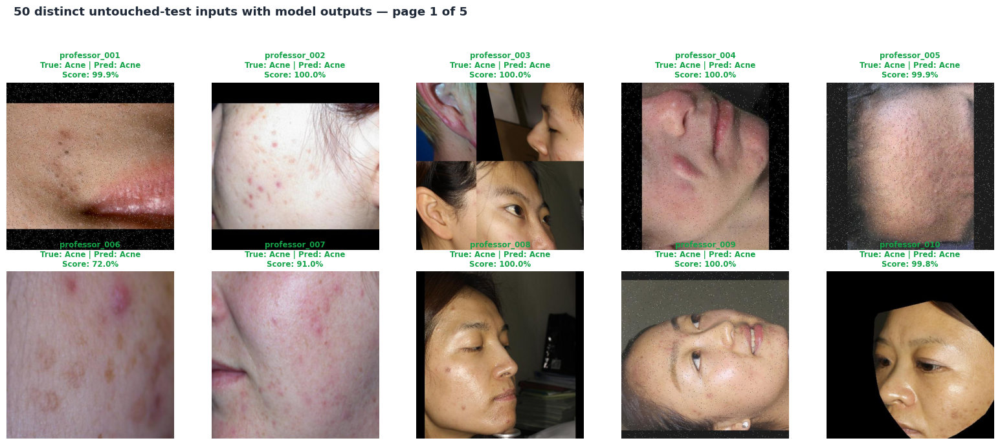

Saved chart: output/charts/professor_50_prediction_gallery_page_1.png


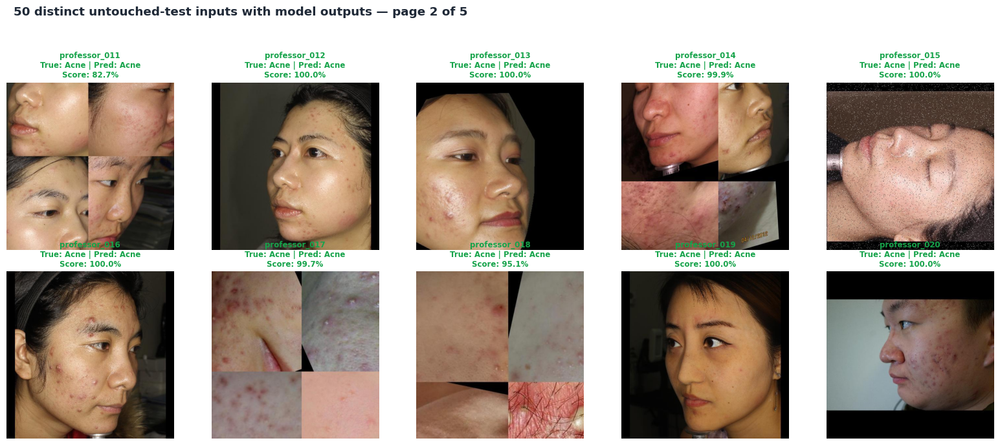

Saved chart: output/charts/professor_50_prediction_gallery_page_2.png


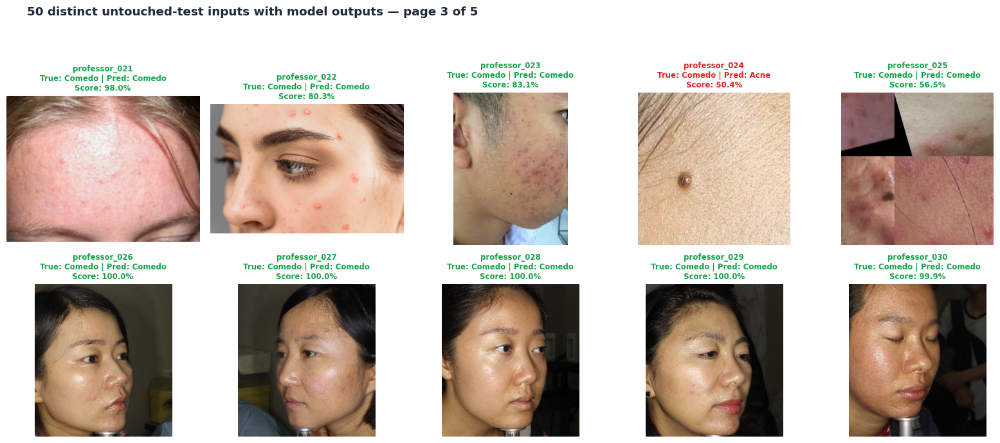

Saved chart: output/charts/professor_50_prediction_gallery_page_3.png


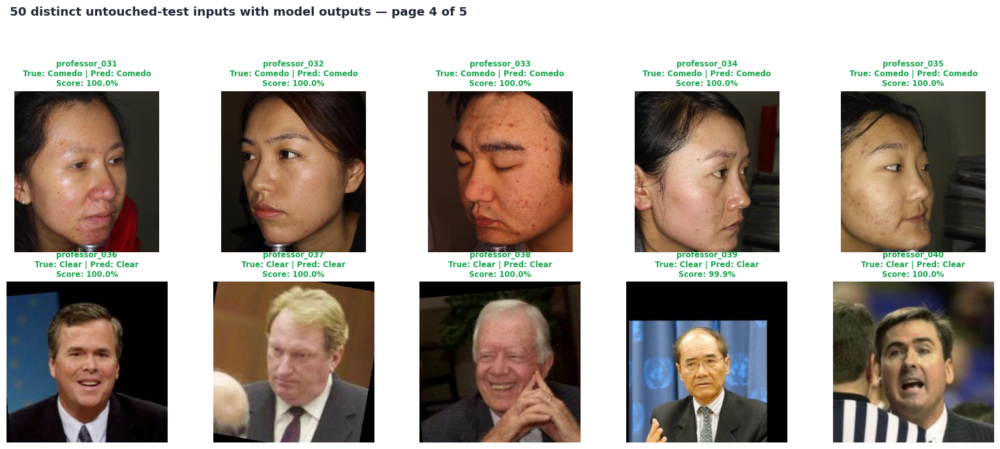

Saved chart: output/charts/professor_50_prediction_gallery_page_4.png


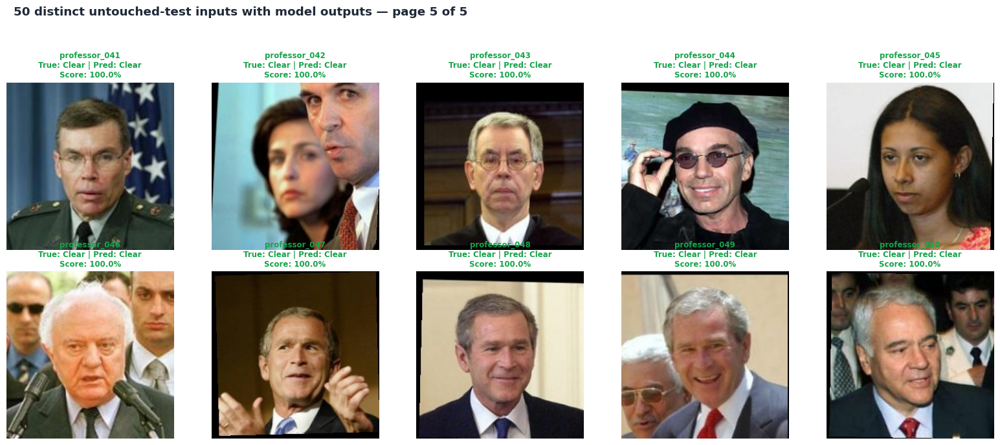

Saved chart: output/charts/professor_50_prediction_gallery_page_5.png
50-image gallery pages saved: 5
Saved table: output/tables/detailed_20_test_predictions.csv
Saved table: output/tables/detailed_20_test_metrics.csv


### Detailed 20-image test demonstration

These rows are a subset of the 50-image gallery. The table exposes the predicted label, correctness, confidence, and probability assigned to every class.

,sample_set,rows,accuracy,balanced_accuracy,macro_f1
0,detailed_20_test_demo,20,0.950,0.944,0.950


,sample_id,path,label,predicted_label,correct,prob_Acne,prob_Comedo,prob_Clear
0,detailed_20_001,dataset/Acne/Train/Acne/acne-comedones-57-v2__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDE3XQ_JPG_jpg.rf.9f7cdf5929d3eb21c56012128c60b0c9.jpg,Acne,Acne,True,0.999,0.000,0.001
1,detailed_20_002,dataset/Acne/Train/Acne/acne-face-1-28__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDFd_jpg.rf.9aa9f2a161bc148ad8bb999449bdd177.jpg,Acne,Acne,True,1.000,0.000,0.000
2,detailed_20_003,dataset/Acne/Train/Acne/acne-face-15__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDFd_jpg.rf.104a3b75cf9b66918bae2c9a81dbf563.jpg,Acne,Acne,True,1.000,0.000,0.000
3,detailed_20_004,dataset/Acne/Train/Acne/acne-face-2-33__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDFd_jpg.rf.c1f4787f3b6babf47f60b6a8c340545b.jpg,Acne,Acne,True,1.000,0.000,0.000
4,detailed_20_005,dataset/Acne/Train/Acne/acne-face-3-18__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDFd_jpg.rf.d1a84e4bb0d23e247b64468711534b9f.jpg,Acne,Acne,True,0.999,0.000,0.001
5,detailed_20_006,dataset/Acne/Train/Acne/acne-face-3-9__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDFd_jpg.rf.06c4eb05a1f4917ebf631e09e03e5a04.jpg,Acne,Acne,True,0.720,0.276,0.003
6,detailed_20_007,dataset/Acne/Train/Acne/acne-face-5-4__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDFd_jpg.rf.b5155ee9548feb1383c2738a1d7742fc.jpg,Acne,Acne,True,0.910,0.089,0.001
7,detailed_20_008,dataset/Acne/Train/Acne/levle1_305_jpg.rf.2d34dc5fa08bb5b582c90c2e5be5e262.jpg,Acne,Acne,True,1.000,0.000,0.000
8,detailed_20_009,dataset/Acne/Train/Comedo/01F3MMYNE0NXTGFZ8T0PGRQPGY_jpeg.rf.7a2f92c428b268332d9d8589e5ececb9.jpg,Comedo,Comedo,True,0.019,0.980,0.001
9,detailed_20_010,dataset/Acne/Train/Comedo/126.jpg,Comedo,Comedo,True,0.197,0.803,0.000


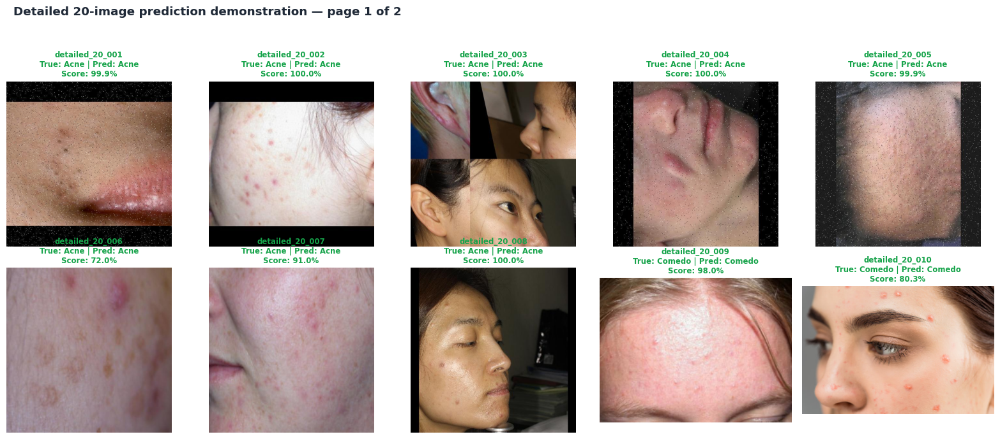

Saved chart: output/charts/detailed_20_prediction_gallery_page_1.png


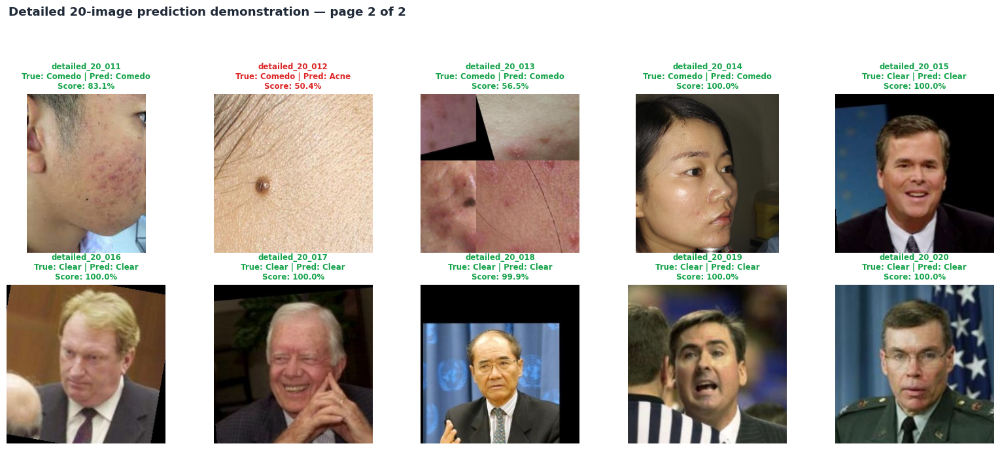

Saved chart: output/charts/detailed_20_prediction_gallery_page_2.png
Saved table: output/tables/detailed_20_gradcam_examples.csv


,sample_id,true_label,predicted_label,correct,overlay_path,top_score
0,detailed_20_001,Acne,Acne,True,output/samples/gradcam_20/detailed_20_001_Acne_Acne.jpg,0.999
1,detailed_20_002,Acne,Acne,True,output/samples/gradcam_20/detailed_20_002_Acne_Acne.jpg,1.000
2,detailed_20_003,Acne,Acne,True,output/samples/gradcam_20/detailed_20_003_Acne_Acne.jpg,1.000
3,detailed_20_004,Acne,Acne,True,output/samples/gradcam_20/detailed_20_004_Acne_Acne.jpg,1.000
4,detailed_20_005,Acne,Acne,True,output/samples/gradcam_20/detailed_20_005_Acne_Acne.jpg,0.999
5,detailed_20_006,Acne,Acne,True,output/samples/gradcam_20/detailed_20_006_Acne_Acne.jpg,0.720
6,detailed_20_007,Acne,Acne,True,output/samples/gradcam_20/detailed_20_007_Acne_Acne.jpg,0.910
7,detailed_20_008,Acne,Acne,True,output/samples/gradcam_20/detailed_20_008_Acne_Acne.jpg,1.000
8,detailed_20_009,Comedo,Comedo,True,output/samples/gradcam_20/detailed_20_009_Comedo_Comedo.jpg,0.980
9,detailed_20_010,Comedo,Comedo,True,output/samples/gradcam_20/detailed_20_010_Comedo_Comedo.jpg,0.803


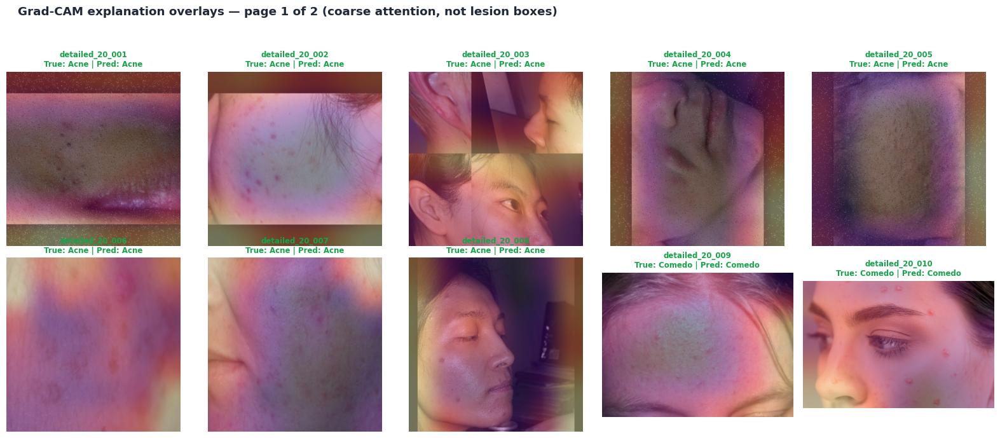

Saved chart: output/charts/detailed_20_gradcam_gallery_page_1.png


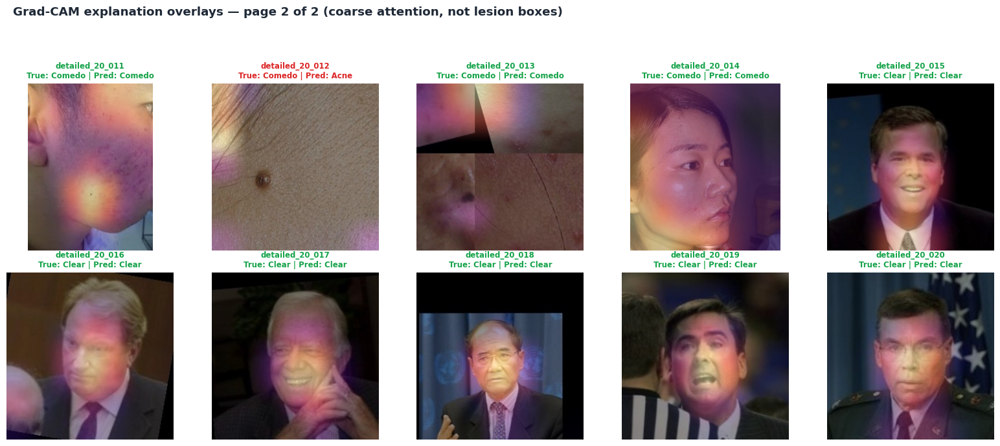

Saved chart: output/charts/detailed_20_gradcam_gallery_page_2.png
20 Grad-CAM overlays saved under output/samples/gradcam_20


In [12]:
PROFESSOR_SAMPLE_ALLOCATION = {'Acne': 20, 'Comedo': 15, 'Clear': 15}
DETAILED_SAMPLE_ALLOCATION = {'Acne': 8, 'Comedo': 6, 'Clear': 6}
assert sum(PROFESSOR_SAMPLE_ALLOCATION.values()) == 50
assert sum(DETAILED_SAMPLE_ALLOCATION.values()) == 20

def stratified_demo_rows(source_frame: pd.DataFrame, allocation: dict, seed: int, id_prefix: str) -> pd.DataFrame:
    selected = []
    for offset, (label, count) in enumerate(allocation.items()):
        pool = source_frame[source_frame['label'].eq(label)].sort_values('path')
        if len(pool) < count:
            raise ValueError(f'Not enough untouched-test rows for {label}: need {count}, found {len(pool)}')
        selected.append(pool.sample(n=count, random_state=seed + offset).sort_values('path'))
    result = pd.concat(selected, ignore_index=True)
    result.insert(0, 'sample_id', [f'{id_prefix}_{index:03d}' for index in range(1, len(result) + 1)])
    result['confidence'] = result[[f'prob_{label}' for label in CLASS_NAMES]].max(axis=1)
    result['predicted_label_id'] = result['predicted_label'].map({label: index for index, label in enumerate(CLASS_NAMES)})
    return result

# These 50 rows are sampled only from the untouched test partition and are reproducible.
professor_rows = stratified_demo_rows(test_predictions, PROFESSOR_SAMPLE_ALLOCATION, SEED + 500, 'professor')
save_table(professor_rows, 'professor_50_test_samples.csv')
professor_summary = pd.DataFrame([
    {
        'sample_set': 'professor_50_stratified_gallery',
        'rows': len(professor_rows),
        'accuracy': float(professor_rows['correct'].mean()),
        'balanced_accuracy': float(balanced_accuracy_score(professor_rows['label_id'], professor_rows['predicted_label_id'])),
        'macro_f1': float(f1_score(professor_rows['label_id'], professor_rows['predicted_label_id'], average='macro', zero_division=0)),
    }
])
save_table(professor_summary, 'professor_50_summary.csv')
display(Markdown('### 50-image professor gallery\n\nThe gallery is stratified for visibility: 20 Acne, 15 Comedo, and 15 Clear. It is not a replacement for the full test evaluation.'))
display(style_table(professor_summary, gradient_columns=['accuracy', 'balanced_accuracy', 'macro_f1']).format({'accuracy': '{:.3f}', 'balanced_accuracy': '{:.3f}', 'macro_f1': '{:.3f}'}))
display(style_table(professor_rows[['sample_id', 'path', 'label', 'predicted_label', 'correct', 'confidence']], gradient_columns=['confidence']).format({'confidence': '{:.3f}'}))

def render_prediction_gallery(frame: pd.DataFrame, filename_prefix: str, title: str, *, rows_per_page: int = 2, columns: int = 5):
    page_size = rows_per_page * columns
    page_count = int(np.ceil(len(frame) / page_size))
    saved_paths = []
    for page_number in range(page_count):
        page = frame.iloc[page_number * page_size:(page_number + 1) * page_size]
        figure, axes = plt.subplots(rows_per_page, columns, figsize=(16, 7))
        figure.patch.set_facecolor('white')
        axes = np.asarray(axes).reshape(-1)
        for axis, (_, row) in zip(axes, page.iterrows()):
            with Image.open(ROOT / row['path']) as image:
                axis.imshow(image.convert('RGB'))
            axis.set_title(
                f"{row['sample_id']}\nTrue: {row['label']} | Pred: {row['predicted_label']}\nScore: {row['confidence']:.1%}",
                fontsize=8.5,
                color='#16A34A' if bool(row['correct']) else '#DC2626',
            )
            axis.axis('off')
        for axis in axes[len(page):]:
            axis.axis('off')
        figure.suptitle(f'{title} — page {page_number + 1} of {page_count}', x=0.03, ha='left', fontweight='bold', color=CHART_COLORS['text'])
        figure.tight_layout(rect=[0, 0, 1, 0.93])
        saved_paths.append(finish_figure(figure, f'{filename_prefix}_page_{page_number + 1}.png'))
    return saved_paths

professor_gallery_paths = render_prediction_gallery(
    professor_rows,
    'professor_50_prediction_gallery',
    '50 distinct untouched-test inputs with model outputs',
)
print(f'50-image gallery pages saved: {len(professor_gallery_paths)}')

# A smaller 20-image subset keeps detailed tables and explanations readable during a viva.
detailed_rows = pd.concat(
    [professor_rows[professor_rows['label'].eq(label)].head(count) for label, count in DETAILED_SAMPLE_ALLOCATION.items()],
    ignore_index=True,
).copy()
detailed_rows['sample_id'] = [f'detailed_20_{index:03d}' for index in range(1, len(detailed_rows) + 1)]
save_table(detailed_rows, 'detailed_20_test_predictions.csv')
detailed_metrics = pd.DataFrame([{
    'sample_set': 'detailed_20_test_demo',
    'rows': len(detailed_rows),
    'accuracy': float(detailed_rows['correct'].mean()),
    'balanced_accuracy': float(balanced_accuracy_score(detailed_rows['label_id'], detailed_rows['predicted_label_id'])),
    'macro_f1': float(f1_score(detailed_rows['label_id'], detailed_rows['predicted_label_id'], average='macro', zero_division=0)),
}])
save_table(detailed_metrics, 'detailed_20_test_metrics.csv')
display(Markdown('### Detailed 20-image test demonstration\n\nThese rows are a subset of the 50-image gallery. The table exposes the predicted label, correctness, confidence, and probability assigned to every class.'))
display(style_table(detailed_metrics, gradient_columns=['accuracy', 'balanced_accuracy', 'macro_f1']).format({'accuracy': '{:.3f}', 'balanced_accuracy': '{:.3f}', 'macro_f1': '{:.3f}'}))
display(style_table(detailed_rows[['sample_id', 'path', 'label', 'predicted_label', 'correct', 'prob_Acne', 'prob_Comedo', 'prob_Clear']], gradient_columns=['prob_Acne', 'prob_Comedo', 'prob_Clear']).format({column: '{:.3f}' for column in ['prob_Acne', 'prob_Comedo', 'prob_Clear']}))
render_prediction_gallery(
    detailed_rows,
    'detailed_20_prediction_gallery',
    'Detailed 20-image prediction demonstration',
)

def gradcam_for_image(model: nn.Module, tensor: torch.Tensor, target_index: int):
    target_layer = [layer for layer in model.modules() if isinstance(layer, nn.Conv2d)][-1]
    activations, gradients = [], []
    forward_handle = target_layer.register_forward_hook(lambda _, __, output: activations.append(output))
    backward_handle = target_layer.register_full_backward_hook(lambda _, __, grad_output: gradients.append(grad_output[0]))
    try:
        model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logits = model(tensor)
            probabilities = torch.softmax(logits, dim=1)[0]
            logits[0, target_index].backward()
        activation = activations[0].detach()
        gradient = gradients[0].detach()
        weights = gradient.mean(dim=(2, 3), keepdim=True)
        heatmap = (weights * activation).sum(dim=1).squeeze(0).cpu().numpy()
        heatmap = np.maximum(heatmap, 0)
        heatmap = heatmap / (heatmap.max() + 1e-8)
        return probabilities.detach().cpu().numpy(), heatmap
    finally:
        forward_handle.remove()
        backward_handle.remove()
        model.zero_grad(set_to_none=True)

gradcam_dir = SAMPLE_DIR / 'gradcam_20'
gradcam_dir.mkdir(parents=True, exist_ok=True)
gradcam_rows = []
for _, row in detailed_rows.iterrows():
    source_path = ROOT / row['path']
    with Image.open(source_path) as source_image:
        source_image = ImageOps.exif_transpose(source_image).convert('RGB')
        tensor = eval_transform(source_image).unsqueeze(0).to(DEVICE)
        predicted_index = CLASS_NAMES.index(row['predicted_label'])
        probabilities, heatmap = gradcam_for_image(final_model, tensor, predicted_index)
        heatmap_image = Image.fromarray(np.uint8(plt.get_cmap('magma')(heatmap)[..., :3] * 255)).resize(source_image.size)
        overlay = Image.blend(source_image, heatmap_image.convert('RGB'), alpha=0.45)
        output_path = gradcam_dir / f"{row['sample_id']}_{row['label']}_{row['predicted_label']}.jpg"
        overlay.save(output_path, quality=92)
        gradcam_rows.append({
            'sample_id': row['sample_id'],
            'true_label': row['label'],
            'predicted_label': row['predicted_label'],
            'correct': bool(row['correct']),
            'overlay_path': relative_path(output_path),
            'top_score': float(probabilities[predicted_index]),
        })
gradcam_table = pd.DataFrame(gradcam_rows)
save_table(gradcam_table, 'detailed_20_gradcam_examples.csv')
display(style_table(gradcam_table, gradient_columns=['top_score']).format({'top_score': '{:.3f}'}))

gradcam_page_size = 10
gradcam_page_count = int(np.ceil(len(gradcam_table) / gradcam_page_size))
for page_number in range(gradcam_page_count):
    page = gradcam_table.iloc[page_number * gradcam_page_size:(page_number + 1) * gradcam_page_size]
    figure, axes = plt.subplots(2, 5, figsize=(16, 7))
    figure.patch.set_facecolor('white')
    axes = np.asarray(axes).reshape(-1)
    for axis, (_, row) in zip(axes, page.iterrows()):
        with Image.open(ROOT / row['overlay_path']) as image:
            axis.imshow(image.convert('RGB'))
        axis.set_title(
            f"{row['sample_id']}\nTrue: {row['true_label']} | Pred: {row['predicted_label']}",
            fontsize=8.5,
            color='#16A34A' if bool(row['correct']) else '#DC2626',
        )
        axis.axis('off')
    for axis in axes[len(page):]:
        axis.axis('off')
    figure.suptitle(
        f'Grad-CAM explanation overlays — page {page_number + 1} of {gradcam_page_count} (coarse attention, not lesion boxes)',
        x=0.03, ha='left', fontweight='bold', color=CHART_COLORS['text'],
    )
    figure.tight_layout(rect=[0, 0, 1, 0.93])
    finish_figure(figure, f'detailed_20_gradcam_gallery_page_{page_number + 1}.png')
print(f'20 Grad-CAM overlays saved under {relative_path(gradcam_dir)}')

## 12. Final evidence-based conclusion

This section compares training and unseen-test behavior without hiding the gap. A large train-to-test macro-F1 difference suggests overfitting or shortcut learning; a small gap does not prove clinical validity. The conclusion records the dataset caveat, the achieved test fraction, and whether the present run is a one-epoch smoke execution or the requested full training schedule.

In [13]:
train_metrics = next(row for row in metric_rows if row['split'] == 'train')
validation_metrics = next(row for row in metric_rows if row['split'] == 'validation')
test_metrics = next(row for row in metric_rows if row['split'] == 'test')
macro_f1_gap = train_metrics['macro_f1'] - test_metrics['macro_f1']
conclusion_lines = [
    f"The untouched test partition contains {len(test_df):,} rows ({len(test_df) / len(clean_manifest):.2%} of the deduplicated data), while the training pool contains {len(train_pool_df):,} rows.",
    f"The final test accuracy is {test_metrics['accuracy']:.2%}, balanced accuracy is {test_metrics['balanced_accuracy']:.2%}, and macro-F1 is {test_metrics['macro_f1']:.2%}.",
    f"The train-to-test macro-F1 gap is {macro_f1_gap:.3f}; this gap is a model/data diagnostic, not evidence of clinical reliability.",
    'The model was selected using validation macro-F1; the test set was not used for checkpoint selection.',
    'The Clear label and the dimensions-only artifact baseline mean the current experiment should be described as dataset-label classification, not medical diagnosis.',
    'The 50-image gallery and 20-image detailed subset are demonstrations drawn from the untouched test partition; they do not replace the full test evaluation.',
]
if EXECUTION_PROFILE != 'full' or EPOCHS < FULL_RUN_MIN_EPOCHS:
    conclusion_lines.append(f"This saved artifact was produced under the '{EXECUTION_PROFILE}' profile with {EPOCHS} requested epoch(s); it is a pipeline-verification smoke run, not the final tuned training result.")
display(Markdown('### Conclusion\n\n' + '\n'.join(f'- {line}' for line in conclusion_lines)))
save_text('\n'.join(f'- {line}' for line in conclusion_lines), 'final_conclusion.md')

### Conclusion

- The untouched test partition contains 3,191 rows (20.00% of the deduplicated data), while the training pool contains 12,762 rows.
- The final test accuracy is 98.93%, balanced accuracy is 94.93%, and macro-F1 is 94.73%.
- The train-to-test macro-F1 gap is 0.043; this gap is a model/data diagnostic, not evidence of clinical reliability.
- The model was selected using validation macro-F1; the test set was not used for checkpoint selection.
- The Clear label and the dimensions-only artifact baseline mean the current experiment should be described as dataset-label classification, not medical diagnosis.
- The 50-image gallery and 20-image detailed subset are demonstrations drawn from the untouched test partition; they do not replace the full test evaluation.

Saved text: output/tables/final_conclusion.md


WindowsPath('D:/academic assignment 2026/acne cnn/output/tables/final_conclusion.md')

## 13. Export the Flask model contract and run manifest

This cell writes the exact class order, preprocessing values, metadata, hashes, and output manifest used by Flask. The best and last checkpoints are saved during training; this cell packages the best checkpoint for inference and records whether the run was full or a smoke verification. No training happens inside Flask.

In [14]:
preprocessing_config = {
    'image_size': IMAGE_SIZE,
    'mean': IMAGENET_MEAN,
    'std': IMAGENET_STD,
    'color_mode': 'RGB',
}
class_names_payload = CLASS_NAMES
(MODEL_DIR / 'class_names.json').write_text(json.dumps(class_names_payload, indent=2), encoding='utf-8')
(MODEL_DIR / 'preprocessing.json').write_text(json.dumps(preprocessing_config, indent=2), encoding='utf-8')
(OUTPUT_MODEL_DIR / 'class_names.json').write_text(json.dumps(class_names_payload, indent=2), encoding='utf-8')
(OUTPUT_MODEL_DIR / 'preprocessing.json').write_text(json.dumps(preprocessing_config, indent=2), encoding='utf-8')

checkpoint_sha = sha256_file(FINAL_CHECKPOINT)
selected_checkpoint_payload = torch.load(FINAL_CHECKPOINT, map_location='cpu')
selected_checkpoint_epoch = int(selected_checkpoint_payload.get('epoch', 0))
history_path = TABLE_DIR / f'{FINAL_MODEL_NAME}_training_history.csv'
completed_epochs = int(pd.read_csv(history_path)['epoch'].max()) if history_path.exists() else 0
model_metadata = {
    'model_name': FINAL_MODEL_NAME,
    'checkpoint': FINAL_CHECKPOINT.name,
    'class_names': CLASS_NAMES,
    'image_size': IMAGE_SIZE,
    'execution_profile': EXECUTION_PROFILE,
    'run_id': RUN_ID,
    'epochs_requested': int(EPOCHS),
    'epochs_completed': completed_epochs,
    'checkpoint_epoch': selected_checkpoint_epoch,
    'early_stopping_patience': int(PATIENCE),
    'gpu_required_for_submission': bool(REQUIRE_GPU),
    'training_run_is_smoke': EXECUTION_PROFILE != 'full' or EPOCHS < FULL_RUN_MIN_EPOCHS,
    'device_used_for_training': str(DEVICE),
    'exploratory_dataset_labels_only': bool(clear_like_lfw),
    'clinical_diagnosis_supported': False,
    'test_fraction_target': TEST_FRACTION,
    'test_fraction_achieved': len(test_df) / len(clean_manifest),
    'dataset_rows_after_exact_deduplication': int(len(clean_manifest)),
    'test_rows': int(len(test_df)),
    'model_sha256': checkpoint_sha,
    'test_metrics': test_metrics,
}
(MODEL_DIR / 'model_metadata.json').write_text(json.dumps(model_metadata, indent=2), encoding='utf-8')
(OUTPUT_MODEL_DIR / 'model_metadata.json').write_text(json.dumps(model_metadata, indent=2), encoding='utf-8')
write_run_state(
    'completed',
    completed_epochs=completed_epochs,
    selected_checkpoint=relative_path(FINAL_CHECKPOINT),
    selected_checkpoint_epoch=selected_checkpoint_epoch,
    model_sha256=checkpoint_sha,
    message='Training, evaluation, Grad-CAM export, and Flask contract completed successfully.',
)

output_files = sorted(relative_path(path) for path in OUTPUT_ROOT.rglob('*') if path.is_file())
output_manifest = {
    'output_root': relative_path(OUTPUT_ROOT),
    'files': output_files,
    'model_checkpoint': relative_path(FINAL_CHECKPOINT),
    'model_sha256': checkpoint_sha,
    'flask_contract': [relative_path(MODEL_DIR / name) for name in ['class_names.json', 'preprocessing.json', 'model_metadata.json', FINAL_CHECKPOINT.name]],
}
save_json(output_manifest, 'output_manifest.json', compatibility_copy=False)

export_table = pd.DataFrame([
    {'artifact': 'best checkpoint', 'path': relative_path(FINAL_CHECKPOINT)},
    {'artifact': 'class names', 'path': relative_path(MODEL_DIR / 'class_names.json')},
    {'artifact': 'preprocessing', 'path': relative_path(MODEL_DIR / 'preprocessing.json')},
    {'artifact': 'metadata', 'path': relative_path(MODEL_DIR / 'model_metadata.json')},
    {'artifact': '50-sample gallery table', 'path': relative_path(TABLE_DIR / 'professor_50_test_samples.csv')},
    {'artifact': '20-sample detailed table', 'path': relative_path(TABLE_DIR / 'detailed_20_test_predictions.csv')},
    {'artifact': 'train-validation-test comparison', 'path': relative_path(TABLE_DIR / f'{FINAL_MODEL_NAME}_performance_by_split.csv')},
])
save_table(export_table, 'flask_export_manifest.csv', compatibility_copy=False)
display(style_table(export_table))

Saved JSON: output/tables/output_manifest.json
Saved table: output/tables/flask_export_manifest.csv


,artifact,path
0,best checkpoint,model/efficientnet_b0_best.pt
1,class names,model/class_names.json
2,preprocessing,model/preprocessing.json
3,metadata,model/model_metadata.json
4,50-sample gallery table,output/tables/professor_50_test_samples.csv
5,20-sample detailed table,output/tables/detailed_20_test_predictions.csv
6,train-validation-test comparison,output/tables/efficientnet_b0_performance_by_split.csv


## 14. Reproducibility and limitations

The random seed is fixed at 42, preprocessing is recorded, the test partition is group-separated, and each epoch saves recoverable checkpoints. The current data still has source/dimension shortcuts and a non-clinical Clear label. Therefore the notebook is suitable as an academic exploratory CNN project and Flask demonstration, but it is not evidence for deployment as a medical diagnostic system.